<a href="https://colab.research.google.com/github/ArthurLopes985/InteligenciaArtificial_atividades/blob/main/Exercicio_ArvoreDecis%C3%A3o_FlorestaAleat%C3%B3ria_Boosting_Arthur_Lopes_de_Oliveira_6D_6P.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 0. Imports

In [3]:
import pandas as pd
import sqlite3 as sql
import seaborn as sns
import matplotlib.pyplot as plt
import numpy as np
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay, classification_report, r2_score, mean_absolute_error
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, RandomForestRegressor, GradientBoostingRegressor
from sklearn.linear_model import LinearRegression

Para iniciar a atividade, foram importadas as bibliotecas necessárias para a análise dos dados, a criação de gráficos e a construção dos modelos de aprendizado de máquina.

A biblioteca Pandas é utilizada para manipular os dados em formato de tabela (DataFrame). O Seaborn e o Matplotlib são responsáveis pela criação e visualização dos gráficos.

Já as bibliotecas do Scikit-learn são utilizadas para dividir os dados em conjuntos de treino e teste (`train_test_split`), realizar validação cruzada (`cross_val_score`), organizar as etapas do processamento em um pipeline (`Pipeline`), padronizar as características (`StandardScaler`) e treinar o modelo SVM (`SVC`).

Também foram importadas ferramentas para buscar os melhores hiperparâmetros (`GridSearchCV`), calcular a acurácia (`accuracy_score`), gerar e visualizar matrizes de confusão (`confusion_matrix` e `ConfusionMatrixDisplay`) e apresentar outras métricas de classificação (`classification_report`).

Por fim, foram importados os modelos Árvore de Decisão, Floresta Aleatória e Gradient Boosting, que serão utilizados para comparar os resultados obtidos pelo SVM.

# 1. Breast Cancer Wisconsin

In [ ]:
import kagglehub
path = kagglehub.dataset_download("uciml/breast-cancer-wisconsin-data")

Using Colab cache for faster access to the 'breast-cancer-wisconsin-data' dataset.


In [ ]:
dataframe = pd.read_csv("/kaggle/input/breast-cancer-wisconsin-data/data.csv")

Nesta etapa, foi utilizado o conjunto de dados Breast Cancer Wisconsin, disponibilizado no Kaggle. A biblioteca `kagglehub` realiza o download do dataset, enquanto a função `pd.read_csv()` lê o arquivo CSV e armazena seus dados em um DataFrame do Pandas, permitindo a análise e o processamento das informações.

## 1.1. Verificar dados

In [ ]:
dataframe.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    object 
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             5

In [ ]:
dataframe.head()

,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [ ]:
dataframe.shape

(569, 33)

In [ ]:
dataframe.describe()

,id,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
count,5.690000e+02,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,0.0
mean,3.037183e+07,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,...,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946,NaN
std,1.250206e+08,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,...,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061,NaN
min,8.670000e+03,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,...,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040,NaN
25%,8.692180e+05,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,...,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460,NaN
50%,9.060240e+05,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,...,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040,NaN
75%,8.813129e+06,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,...,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080,NaN
max,9.113205e+08,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,...,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500,NaN


In [ ]:
dataframe.isnull().sum()

,0
id,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0


Antes de iniciar o treinamento dos modelos, foram realizadas algumas verificações para compreender a estrutura e a qualidade dos dados.

A função `info()` apresenta os tipos das colunas e a quantidade de valores não nulos. A função `head()` permite visualizar as primeiras linhas, enquanto `shape` informa a quantidade de linhas e colunas do dataset.

O método `describe()` apresenta estatísticas descritivas das variáveis numéricas, como média, desvio padrão, valores mínimos e máximos. Por fim, `isnull().sum()` verifica a quantidade de valores ausentes em cada coluna.

Essas verificações ajudam a identificar possíveis inconsistências e a decidir quais tratamentos são necessários antes do treinamento dos modelos.

## 1.2. Limpar colunas desnecessarias

In [ ]:
dataframe = dataframe.drop("id", axis = 1)

A coluna `id` foi removida porque contém identificadores dos registros, que não representam características relevantes do tumor para a classificação. Sua utilização como variável preditora poderia introduzir informações sem significado clínico para o modelo.

In [ ]:
dataframe = dataframe.drop("Unnamed: 32", axis = 1)

A coluna `Unnamed: 32` foi removida porque não contém informações úteis para a análise, apresentando valores ausentes. Sua exclusão evita manter uma coluna desnecessária no conjunto de dados.

Após as remoções, o DataFrame foi novamente visualizado e verificado para confirmar a estrutura das colunas restantes e conferir a existência de valores ausentes.

In [ ]:
dataframe.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [ ]:
dataframe.isnull().sum()

,0
diagnosis,0
radius_mean,0
texture_mean,0
perimeter_mean,0
area_mean,0
smoothness_mean,0
compactness_mean,0
concavity_mean,0
concave points_mean,0
symmetry_mean,0


## 1.3. Graficos para melhor visualização

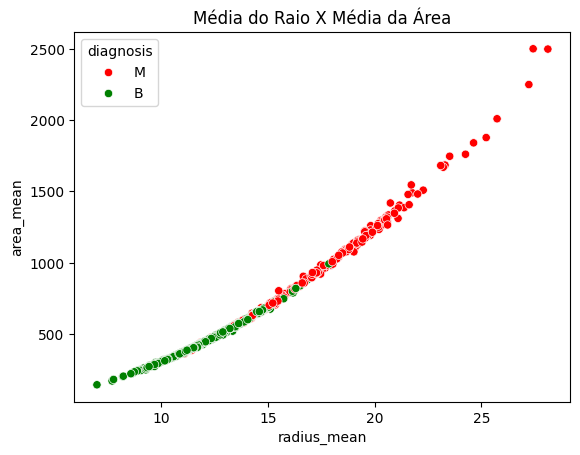

In [ ]:
sns.scatterplot(
    data=dataframe,
    x="radius_mean",
    y="area_mean",
    hue="diagnosis",
    palette = {"M": "red","B": "green"}
)

plt.title("Média do Raio X Média da Área")
plt.show()

#radius, perimeter, area bom= baixo/medio
# concavity, concave points bom = perto de 0
#texture, smoothness bom = suave
#compactness symetry, fractal_dimension bom = simetrico

Neste gráfico, foram comparados o raio médio e a área média dos tumores, utilizando cores diferentes para representar os diagnósticos maligno (M) e benigno (B).

O objetivo é observar se essas características apresentam padrões que ajudem a distinguir as duas classes. Uma separação visual entre os grupos pode indicar que essas variáveis são úteis para a classificação, embora a confirmação de sua importância dependa da avaliação do modelo.

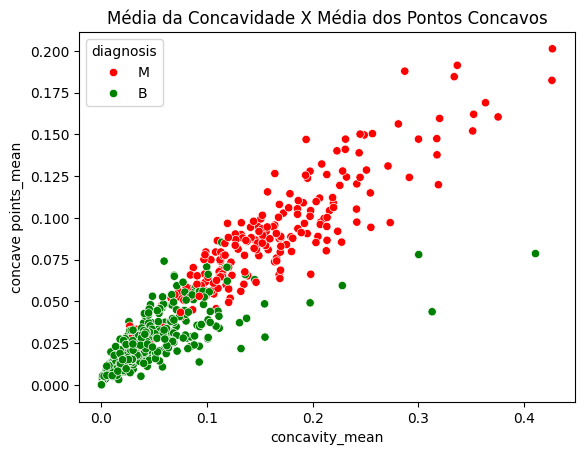

In [ ]:
sns.scatterplot(
    data=dataframe,
    x="concavity_mean",
    y="concave points_mean",
    hue="diagnosis",
    palette = {"M": "red","B": "green"}
)

plt.title("Média da Concavidade X Média dos Pontos Concavos")
plt.show()

#radius, perimeter, area bom= baixo/medio
# concavity, concave points bom = perto de 0
#texture, smoothness bom = suave
#compactness symetry, fractal_dimension bom = simetrico

Neste gráfico, foram comparadas a concavidade média e a quantidade relativa de pontos côncavos representada pela variável `concave points_mean`.

A visualização permite verificar se os tumores malignos e benignos apresentam distribuições diferentes nessas características. A concentração de observações em regiões distintas pode ajudar a identificar padrões relevantes para o aprendizado de máquina.

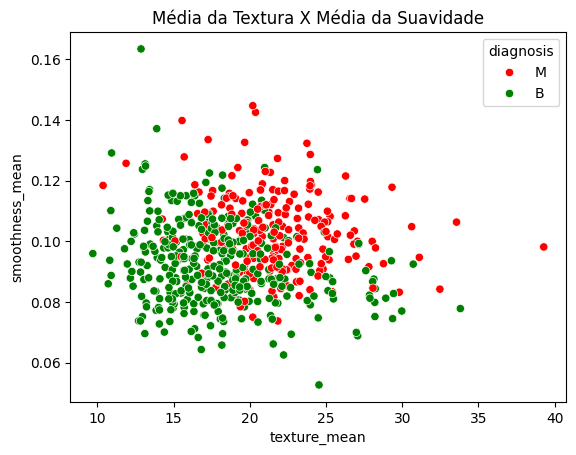

In [ ]:
sns.scatterplot(
    data=dataframe,
    x="texture_mean",
    y="smoothness_mean",
    hue="diagnosis",
    palette = {"M": "red","B": "green"}
)

plt.title("Média da Textura X Média da Suavidade")
plt.show()

#radius, perimeter, area bom= baixo/medio
# concavity, concave points bom = perto de 0
#texture, smoothness bom = suave
#compactness symetry, fractal_dimension bom = simetrico

Neste gráfico, foram analisadas as relações entre a textura média e a suavidade média dos tumores.

A comparação busca identificar possíveis diferenças na distribuição dessas características entre as classes malignas e benignas. Caso os grupos apresentem grande sobreposição, essas variáveis isoladamente podem ter menor capacidade de separar os diagnósticos.

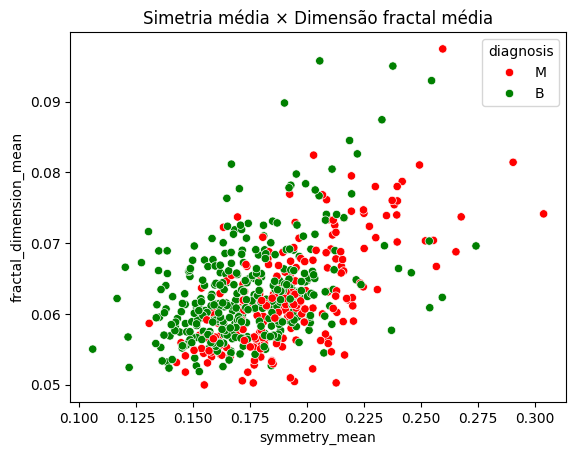

In [ ]:
sns.scatterplot(
    data=dataframe,
    x="symmetry_mean",
    y="fractal_dimension_mean",
    hue="diagnosis",
    palette = {"M": "red","B": "green"}
)

plt.title("Simetria média × Dimensão fractal média")
plt.show()

#radius, perimeter, area bom= baixo/medio
# concavity, concave points bom = perto de 0
#texture, smoothness bom = suave
#compactness symetry, fractal_dimension bom = simetrico

Neste gráfico, foram comparadas a simetria média e a dimensão fractal média dos tumores. O objetivo é observar se essas características apresentam padrões distintos para os diagnósticos maligno e benigno.

A visualização auxilia na exploração dos dados, mas não permite concluir, sozinha, se um tumor é benigno ou maligno. A classificação depende da análise conjunta das características e da avaliação do modelo treinado.

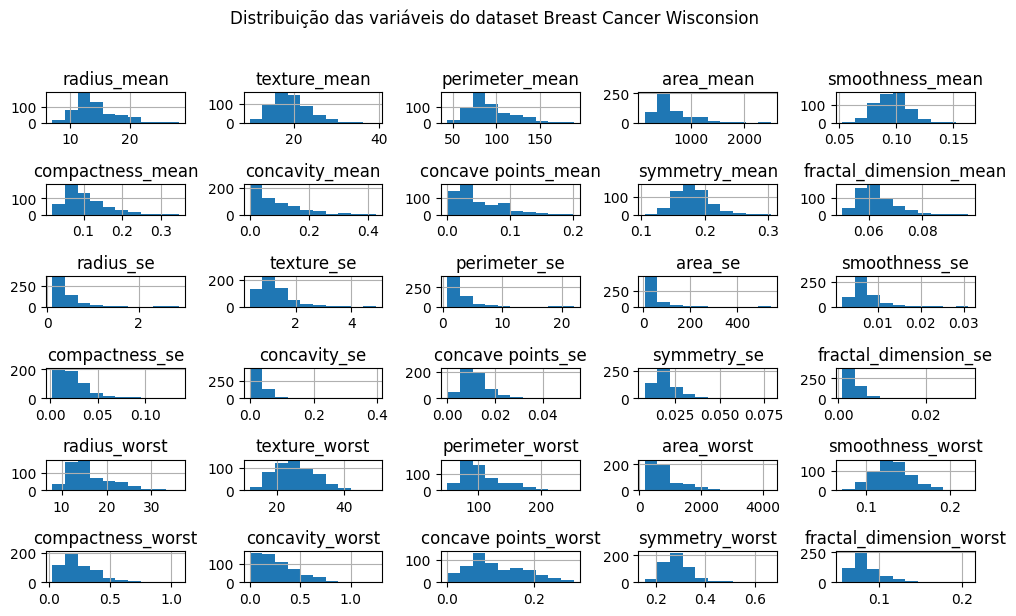

In [ ]:
dataframe[dataframe.columns].hist(figsize=(10, 6))
plt.suptitle("Distribuição das variáveis do dataset Breast Cancer Wisconsion", y=1.02)
plt.tight_layout()
plt.show()

Nesta etapa, foram criados histogramas para visualizar a distribuição das variáveis numéricas do dataset. Eles permitem observar a concentração dos valores, a dispersão e possíveis assimetrias nas distribuições.

Essa análise exploratória ajuda a compreender melhor os dados antes da modelagem e a identificar características que mereçam uma investigação mais detalhada.

## 1.4. Pasando dados para X(caracteristicas) e Y(alvo)

In [ ]:
x = dataframe[[
    "radius_mean",
    "area_mean",
    "perimeter_mean"
]]
y = dataframe["diagnosis"]
print("Formato de x: ", x.shape)
print("Formato de y: ", y.shape)

Formato de x:  (569, 3)
Formato de y:  (569,)


Nesta etapa, foram definidas as variáveis que serão utilizadas no treinamento do modelo.

A variável `x` contém três características numéricas: raio médio (`radius_mean`), área média (`area_mean`) e perímetro médio (`perimeter_mean`). Elas foram selecionadas por apresentarem padrões visuais potencialmente úteis para distinguir os diagnósticos nos gráficos anteriores.

A variável `y` contém o diagnóstico de cada registro, classificado como maligno (M) ou benigno (B). Ela representa o alvo que o modelo deverá aprender a prever.

Por fim, foram exibidas as dimensões de `x` e `y` para verificar a quantidade de registros e confirmar que as variáveis foram separadas corretamente.

## 1.5. Separação em treino e teste

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 42, stratify = y)
print("X_train: ", x_train.shape)
print("X_test: ", x_test.shape)
print("Y_train: ", y_train.shape)
print("Y_test: ", y_test.shape)
print("Distribuição em y_train: ", y_train.value_counts())
print("Distribuição em y_test: ", y_test.value_counts())

X_train:  (455, 3)
X_test:  (114, 3)
Y_train:  (455,)
Y_test:  (114,)
Distribuição em y_train:  diagnosis
B    285
M    170
Name: count, dtype: int64
Distribuição em y_test:  diagnosis
B    72
M    42
Name: count, dtype: int64


Nesta etapa, o conjunto de dados foi dividido em duas partes: 80% para treinamento e 20% para teste.

O conjunto de treinamento é utilizado para ajustar os modelos e selecionar os hiperparâmetros. Já o conjunto de teste permite avaliar o desempenho do modelo em dados que não foram utilizados diretamente durante o treinamento.

O parâmetro `random_state=42` permite reproduzir a mesma divisão dos dados em execuções posteriores. Já `stratify=y` preserva aproximadamente a proporção das classes malignas e benignas nos dois conjuntos.

Por fim, foram exibidas as dimensões de cada conjunto e a distribuição dos diagnósticos, permitindo conferir se a divisão ocorreu conforme o esperado.

## 1.6. SVM

In [ ]:
pipeline = Pipeline([
   ("scaler", StandardScaler()),
   ("svm", SVC())
])
gridpr = {"svm__kernel":['linear', 'rbf', 'poly'],
          'svm__C':[1, 10, 100],
          'svm__gamma': [1, 0.1, 0.01]}
grid = GridSearchCV(
    pipeline,
    param_grid=gridpr,
    cv=5,
    scoring='accuracy'
)
grid.fit(x_train, y_train)
print("Melhores parametros: ", grid.best_params_)
print("Melhor Acuracia: ", grid.best_score_)
modelo=grid.best_estimator_
y_prever = modelo.predict(x_test)
precisao = accuracy_score(y_test, y_prever)
print(f"A precisão do modelo foi: {precisao*100:.2f}%")

Melhores parametros:  {'svm__C': 100, 'svm__gamma': 1, 'svm__kernel': 'rbf'}
Melhor Acuracia:  0.9054945054945055
A precisão do modelo foi: 89.47%


Nesta etapa, foi criado um pipeline contendo o `StandardScaler` e o classificador SVM (`SVC`).

O `StandardScaler` padroniza as características numéricas, colocando-as em escalas comparáveis. Esse procedimento é importante para o SVM, pois diferenças muito grandes entre as escalas das variáveis podem influenciar o processo de classificação.

Em seguida, foi utilizado o `GridSearchCV` para testar diferentes combinações de hiperparâmetros: os kernels linear, RBF e polinomial, diferentes valores de `C` e diferentes valores de `gamma`. A validação cruzada com quatro divisões foi utilizada para comparar essas combinações pela acurácia.

Após o ajuste, foram apresentados os melhores hiperparâmetros e a melhor acurácia média obtida na validação cruzada. O melhor pipeline foi armazenado em `modelo`, utilizado para realizar previsões no conjunto de teste.

Por fim, a função `accuracy_score()` calculou a acurácia das previsões, indicando a proporção de classificações corretas entre todos os registros do conjunto de teste.

### 1.6.1. Validação Cruzada

In [ ]:
validacao_cruzada = cross_val_score(modelo, x, y, cv = 5)
print("Precisão em cada verificação: ", validacao_cruzada)
print(f"A média de precisao foi: {validacao_cruzada.mean()*100:.2f}%")
print(f"O desvio padrão de precisao foi: {validacao_cruzada.std()*100:.2f}%")

Precisão em cada verificação:  [0.85964912 0.88596491 0.9122807  0.93859649 0.92035398]
A média de precisao foi: 90.34%
O desvio padrão de precisao foi: 2.77%


Nesta etapa, foi realizada uma validação cruzada com cinco divisões (`cv=5`) utilizando o modelo selecionado anteriormente.

O procedimento avalia o modelo em diferentes divisões dos dados e permite observar como seu desempenho varia entre elas. A média das acurácias resume o resultado obtido, enquanto o desvio padrão indica a variação entre as avaliações.

Uma média elevada acompanhada de um desvio padrão menor pode indicar resultados mais consistentes. Entretanto, como o modelo e seus hiperparâmetros foram selecionados anteriormente utilizando parte desses mesmos dados, essa avaliação não constitui uma estimativa totalmente independente do desempenho. Para isso, seria necessário reservar dados que não participassem da seleção do modelo ou utilizar uma estratégia de validação aninhada.

### 1.6.2. Matriz de Confusão

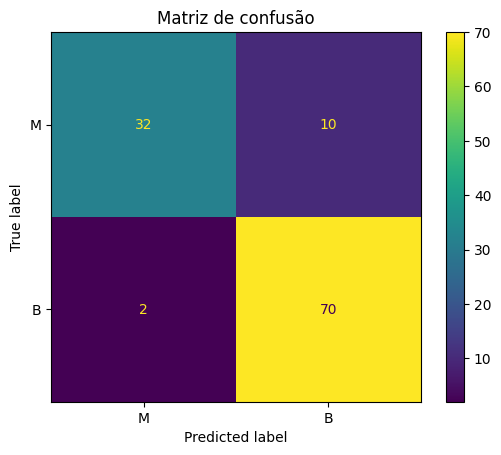

In [ ]:
matriz = confusion_matrix(y_test, y_prever, labels=["M", "B"])
disp = ConfusionMatrixDisplay(confusion_matrix = matriz, display_labels=["M", "B"])
disp.plot()
plt.title("Matriz de confusão")
plt.show()

Nesta etapa, foi criada uma matriz de confusão para comparar os diagnósticos reais com as previsões feitas pelo SVM no conjunto de teste.

As linhas e colunas representam as classes reais e previstas, respectivamente, conforme a organização definida na função. A matriz permite identificar quantos registros foram classificados corretamente e quantos foram confundidos entre as classes.

Essa visualização é especialmente importante neste problema, pois permite analisar separadamente os erros cometidos nas classificações de tumores malignos e benignos.

A quantidade de acertos e erros deve ser interpretada a partir dos valores apresentados na matriz, e não por uma porcentagem isolada sem considerar a organização dos eixos.


### 1.6.3 Relatório

In [ ]:
print("Relatório de classificação do SVM: ")
print(classification_report(y_test, y_prever))

Relatório de classificação do SVM: 
              precision    recall  f1-score   support

           B       0.88      0.97      0.92        72
           M       0.94      0.76      0.84        42

    accuracy                           0.89       114
   macro avg       0.91      0.87      0.88       114
weighted avg       0.90      0.89      0.89       114



Nesta etapa, foi gerado um relatório de classificação utilizando a função `classification_report()`.

O relatório apresenta métricas como precisão (precision), revocação (recall), F1-score e suporte (support) para cada classe. A precisão indica a proporção de previsões de uma classe que estavam corretas; a revocação indica a proporção de registros reais daquela classe que foram identificados corretamente; e o F1-score combina precisão e revocação em uma única métrica.

O suporte representa a quantidade de exemplos reais de cada classe no conjunto de teste. A análise conjunta dessas métricas complementa a acurácia e ajuda a compreender melhor os tipos de erro cometidos pelo modelo.

## 1.7. Arvore de Desição, Boosting e Floresta Aleatória

### 1.7.1 Criando Modelos

In [ ]:
modelos = {
    'Árvore de Decisão': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}
for nome, md in modelos.items():
    md.fit(x_train, y_train)
    print(f'{nome}: treinado')

Árvore de Decisão: treinado
Random Forest: treinado
Gradient Boosting: treinado


Nesta etapa, foram inicializados três modelos de aprendizado de máquina para comparar seus resultados com os do SVM: Árvore de Decisão, Floresta Aleatória (Random Forest) e Gradient Boosting.

A Árvore de Decisão realiza classificações por meio de uma sequência de regras. A Floresta Aleatória combina várias árvores treinadas com aleatoriedade para produzir uma previsão conjunta. Já o Gradient Boosting constrói modelos sequencialmente, buscando melhorar o desempenho a partir dos erros dos modelos anteriores.

Os modelos foram configurados com `random_state=42` para facilitar a reprodução dos resultados. Na Floresta Aleatória, também foi definido o uso de 100 árvores por meio de `n_estimators=100`.

Em seguida, cada modelo foi ajustado utilizando os mesmos dados de treinamento empregados no SVM, permitindo uma comparação mais consistente entre os métodos.

### 1.7.2. Prevendo

In [ ]:
previsoes = {nome: md.predict(x_test) for nome, md in modelos.items()}
print('Valores reais:', y_test)
for nome, y_pred in previsoes.items():
    print(f'{nome}:', y_pred)

Valores reais: 120    B
250    M
375    B
99     M
455    B
      ..
381    B
534    B
448    B
205    M
75     M
Name: diagnosis, Length: 114, dtype: object
Árvore de Decisão: ['B' 'M' 'M' 'M' 'M' 'B' 'B' 'M' 'B' 'M' 'M' 'B' 'M' 'B' 'B' 'B' 'B' 'B'
 'M' 'B' 'B' 'B' 'M' 'M' 'B' 'B' 'B' 'M' 'B' 'M' 'M' 'B' 'M' 'M' 'B' 'B'
 'B' 'B' 'M' 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'M' 'M' 'B' 'B'
 'M' 'M' 'B' 'B' 'B' 'M' 'B' 'B' 'M' 'B' 'B' 'B' 'M' 'M' 'B' 'B' 'M' 'M'
 'M' 'B' 'B' 'B' 'B' 'M' 'B' 'M' 'M' 'M' 'B' 'B' 'B' 'B' 'M' 'M' 'M' 'B'
 'M' 'B' 'M' 'B' 'B' 'B' 'B' 'M' 'B' 'B' 'B' 'B' 'B' 'B' 'M' 'M' 'M' 'M'
 'M' 'B' 'B' 'B' 'M' 'M']
Random Forest: ['B' 'M' 'M' 'B' 'B' 'B' 'B' 'M' 'B' 'B' 'M' 'B' 'M' 'B' 'B' 'B' 'B' 'B'
 'M' 'B' 'B' 'B' 'M' 'M' 'B' 'B' 'B' 'B' 'B' 'M' 'M' 'B' 'M' 'M' 'B' 'B'
 'B' 'B' 'M' 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'B' 'M' 'M' 'B' 'B'
 'B' 'M' 'B' 'B' 'B' 'M' 'B' 'B' 'M' 'B' 'B' 'B' 'M' 'M' 'B' 'B' 'B' 'M'
 'M' 'B' 'B' 'B' 'B' 'M' 'B' 'M' 'M' 'M' 'B' 'B' 'B'

Após o treinamento, cada modelo foi utilizado para prever os diagnósticos presentes no conjunto de teste.

As previsões foram armazenadas em um dicionário, associando o nome de cada modelo aos seus respectivos resultados. Em seguida, foram exibidos os valores reais de `y_test` e as previsões de cada classificador.

Essa etapa permite visualizar as classificações realizadas e preparar os resultados para a avaliação das métricas de desempenho.

### 1.7.3. Avaliação e Comparação

In [ ]:
resultados = []
for nome, y_pred in previsoes.items():
    acuracia = accuracy_score(y_test, y_pred)
    resultados.append({'Modelo': nome, 'Acurácia': acuracia})
    print(f'\n{nome} — Acurácia: {acuracia:.2%}')
    print(classification_report(y_test, y_pred, target_names=["M", "B"], zero_division=0))
pd.DataFrame(resultados).sort_values('Acurácia', ascending=False)


Árvore de Decisão — Acurácia: 83.33%
              precision    recall  f1-score   support

           M       0.88      0.85      0.87        72
           B       0.76      0.81      0.78        42

    accuracy                           0.83       114
   macro avg       0.82      0.83      0.82       114
weighted avg       0.84      0.83      0.83       114


Random Forest — Acurácia: 85.96%
              precision    recall  f1-score   support

           M       0.87      0.92      0.89        72
           B       0.84      0.76      0.80        42

    accuracy                           0.86       114
   macro avg       0.86      0.84      0.85       114
weighted avg       0.86      0.86      0.86       114


Gradient Boosting — Acurácia: 84.21%
              precision    recall  f1-score   support

           M       0.86      0.89      0.88        72
           B       0.80      0.76      0.78        42

    accuracy                           0.84       114
   macro avg      

,Modelo,Acurácia
1,Random Forest,0.859649
2,Gradient Boosting,0.842105
0,Árvore de Decisão,0.833333


Nesta etapa, os modelos foram avaliados utilizando as previsões feitas no conjunto de teste.

A função `accuracy_score()` calculou a acurácia de cada modelo, enquanto `classification_report()` apresentou métricas adicionais para analisar o desempenho nas classes malignas e benignas.

Os resultados de acurácia foram armazenados em uma lista e convertidos em um DataFrame do Pandas. Por fim, a tabela foi ordenada em ordem decrescente de acurácia, facilitando a identificação dos modelos com maior proporção de classificações corretas.

A comparação não deve considerar apenas a acurácia: precisão, revocação e F1-score também são importantes para entender quais modelos apresentam melhor equilíbrio entre as classes e quais cometem erros mais relevantes para o problema.

### 1.7.4 Visualização

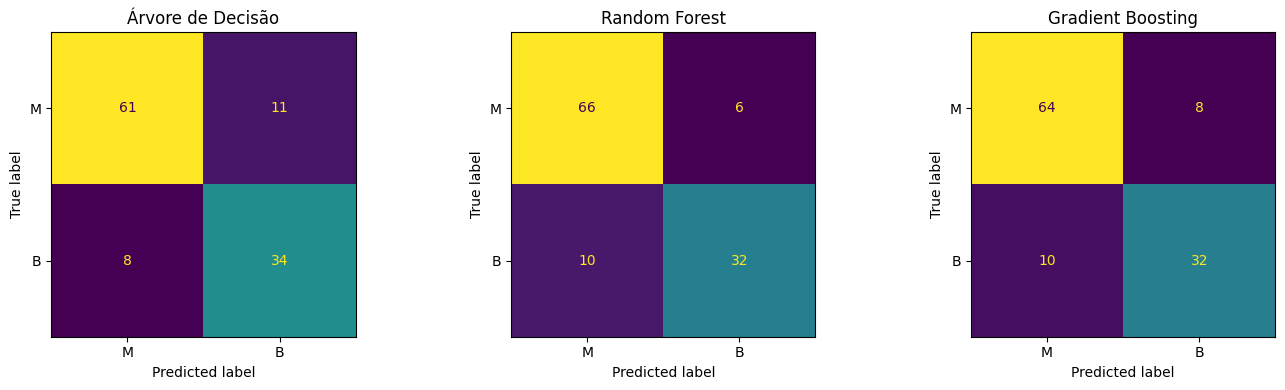

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (nome, y_pred) in zip(axes, previsoes.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred,
        display_labels=["M", "B"], ax=ax, colorbar=False)
    ax.set_title(nome)
plt.tight_layout()
plt.show()

Para complementar a comparação numérica, foram construídas matrizes de confusão para os três modelos, organizadas lado a lado em uma única figura.

Cada matriz permite comparar os diagnósticos reais com as previsões do respectivo classificador, facilitando a identificação de acertos e erros em cada classe.

A visualização conjunta ajuda a perceber diferenças entre os modelos que podem não ser evidentes apenas pela acurácia. Dessa forma, é possível avaliar não somente quantas previsões foram corretas, mas também como os erros se distribuem entre os diagnósticos malignos e benignos.


## 1.8. Interpretando

Neste primeiro dataset, foi desenvolvido um modelo de classificação para distinguir tumores malignos e benignos utilizando características numéricas do conjunto Breast Cancer Wisconsin.

O SVM foi treinado com um pipeline de padronização e teve seus hiperparâmetros selecionados por meio do GridSearchCV. Em seguida, seu desempenho foi avaliado no conjunto de teste e complementado pela análise da matriz de confusão e do relatório de classificação.

Também foram treinados três modelos adicionais: Árvore de Decisão, Floresta Aleatória e Gradient Boosting. A comparação entre eles permite investigar quais métodos apresentaram melhores resultados para as características selecionadas.

Os resultados devem ser interpretados com base nas métricas efetivamente obtidas. Embora uma acurácia maior indique uma proporção superior de classificações corretas, é importante analisar também a revocação da classe maligna, pois deixar de identificar um tumor maligno é um erro especialmente relevante nesse contexto.

Por fim, os resultados representam uma avaliação experimental dos modelos neste conjunto de dados e não devem ser interpretados como uma ferramenta clínica de diagnóstico.

# 2. European Soccer

In [ ]:
import kagglehub
path = kagglehub.dataset_download("hugomathien/soccer")

Using Colab cache for faster access to the 'soccer' dataset.


In [ ]:
caminho = "/kaggle/input/soccer/database.sqlite" # Caminho do banco de dados
conn = sql.connect(caminho) # Criando uma conexão com o banco de dados
query = "SELECT * FROM Player_Attributes LIMIT 300;" # Pegando somente as 300 primeiras linhas da tabela dos atributos dos jogadores
df_jogadores = pd.read_sql_query(query, conn) # Criando um dataframe com os dados do banco de dados
conn.close() # Fechando a conexão
print(df_jogadores) # Printando os atributos dos jogadores

      id  player_fifa_api_id  player_api_id                 date  \
0      1              218353         505942  2016-02-18 00:00:00   
1      2              218353         505942  2015-11-19 00:00:00   
2      3              218353         505942  2015-09-21 00:00:00   
3      4              218353         505942  2015-03-20 00:00:00   
4      5              218353         505942  2007-02-22 00:00:00   
..   ...                 ...            ...                  ...   
295  296              186561          75489  2013-03-15 00:00:00   
296  297              186561          75489  2013-03-01 00:00:00   
297  298              186561          75489  2013-02-22 00:00:00   
298  299              186561          75489  2013-02-15 00:00:00   
299  300              186561          75489  2012-08-31 00:00:00   

     overall_rating  potential preferred_foot attacking_work_rate  \
0                67         71          right              medium   
1                67         71          right

## 2.1. Exploração de dados

In [ ]:
df_jogadores.head() # Mostra o topo do dataframe

,id,player_fifa_api_id,player_api_id,date,overall_rating,potential,preferred_foot,attacking_work_rate,defensive_work_rate,crossing,...,vision,penalties,marking,standing_tackle,sliding_tackle,gk_diving,gk_handling,gk_kicking,gk_positioning,gk_reflexes
0,1,218353,505942,2016-02-18 00:00:00,67,71,right,medium,medium,49,...,54,48,65,69,69,6,11,10,8,8
1,2,218353,505942,2015-11-19 00:00:00,67,71,right,medium,medium,49,...,54,48,65,69,69,6,11,10,8,8
2,3,218353,505942,2015-09-21 00:00:00,62,66,right,medium,medium,49,...,54,48,65,66,69,6,11,10,8,8
3,4,218353,505942,2015-03-20 00:00:00,61,65,right,medium,medium,48,...,53,47,62,63,66,5,10,9,7,7
4,5,218353,505942,2007-02-22 00:00:00,61,65,right,medium,medium,48,...,53,47,62,63,66,5,10,9,7,7


In [ ]:
df_jogadores.shape # Mostra o formato do dataframe

(300, 42)

In [ ]:
df_jogadores.info() # Mostra as informações do dataframe

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 42 columns):
 #   Column               Non-Null Count  Dtype 
---  ------               --------------  ----- 
 0   id                   300 non-null    int64 
 1   player_fifa_api_id   300 non-null    int64 
 2   player_api_id        300 non-null    int64 
 3   date                 300 non-null    object
 4   overall_rating       300 non-null    int64 
 5   potential            300 non-null    int64 
 6   preferred_foot       300 non-null    object
 7   attacking_work_rate  300 non-null    object
 8   defensive_work_rate  300 non-null    object
 9   crossing             300 non-null    int64 
 10  finishing            300 non-null    int64 
 11  heading_accuracy     300 non-null    int64 
 12  short_passing        300 non-null    int64 
 13  volleys              300 non-null    int64 
 14  dribbling            300 non-null    int64 
 15  curve                300 non-null    int64 
 16  free_kic

In [ ]:
df_jogadores.describe() # Descreve algumas informações do dataframe

,id,player_fifa_api_id,player_api_id,overall_rating,potential,crossing,finishing,heading_accuracy,short_passing,volleys,...,vision,penalties,marking,standing_tackle,sliding_tackle,gk_diving,gk_handling,gk_kicking,gk_positioning,gk_reflexes
count,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,...,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000,300.000000
mean,150.500000,163228.870000,119090.390000,70.283333,75.440000,62.700000,53.973333,55.670000,68.006667,53.203333,...,64.076667,59.536667,50.203333,51.716667,50.156667,11.670000,11.523333,15.896667,13.046667,12.990000
std,86.746758,52702.174751,128203.682099,7.519188,6.535706,15.491394,17.071734,13.818984,11.601232,18.011757,...,15.185722,13.706991,20.678022,21.744404,20.984278,7.226005,6.510305,16.880635,7.223463,7.357332
min,1.000000,17725.000000,23780.000000,47.000000,56.000000,12.000000,15.000000,16.000000,23.000000,14.000000,...,15.000000,28.000000,15.000000,15.000000,12.000000,5.000000,5.000000,5.000000,6.000000,6.000000
25%,75.750000,152747.000000,30572.000000,66.750000,70.000000,57.000000,43.000000,49.750000,64.000000,32.000000,...,58.000000,52.000000,30.000000,29.000000,34.750000,7.000000,7.000000,6.000000,9.000000,10.000000
50%,150.500000,186170.000000,75489.000000,70.000000,76.000000,64.000000,58.000000,58.000000,67.500000,59.000000,...,65.000000,61.000000,56.000000,61.000000,60.000000,12.000000,11.000000,9.000000,11.000000,11.000000
75%,225.250000,189615.000000,162549.000000,77.000000,80.000000,74.250000,67.000000,66.000000,77.000000,68.250000,...,76.000000,69.000000,67.000000,72.000000,68.000000,14.000000,12.000000,13.000000,15.000000,14.000000
max,300.000000,221280.000000,564793.000000,84.000000,90.000000,82.000000,79.000000,82.000000,84.000000,81.000000,...,83.000000,84.000000,82.000000,83.000000,78.000000,53.000000,41.000000,73.000000,51.000000,53.000000


In [ ]:
df_jogadores.isnull().sum() # Verifica se tem informações nulas

,0
id,0
player_fifa_api_id,0
player_api_id,0
date,0
overall_rating,0
potential,0
preferred_foot,0
attacking_work_rate,0
defensive_work_rate,0
crossing,0


## 2.2. Algumas Visualizações

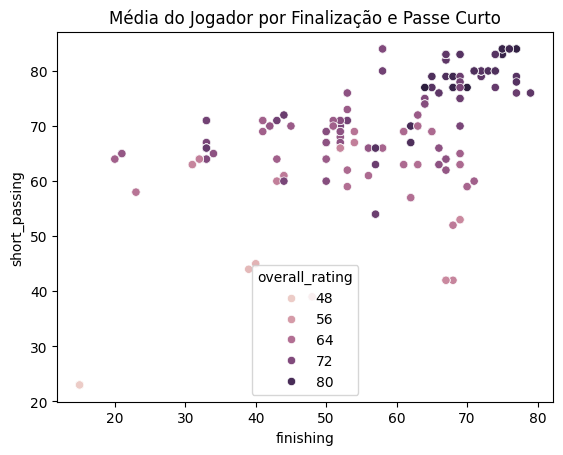

In [ ]:
sns.scatterplot( # Usando Seaborn para gerar um grafico de dispersão
    data=df_jogadores,
    x="finishing",
    y="short_passing",
    hue="overall_rating"
)

plt.title("Média do Jogador por Finalização e Passe Curto")
plt.show()

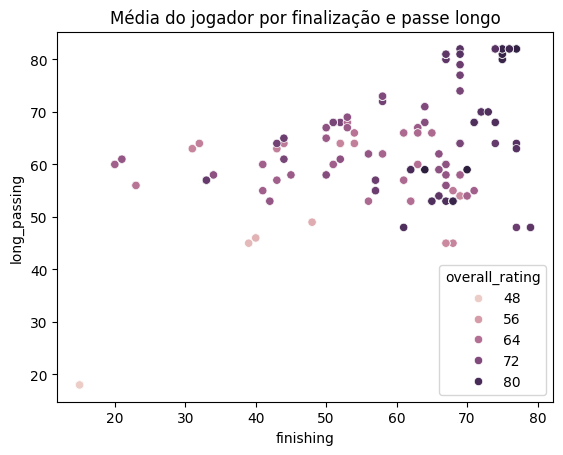

In [ ]:
sns.scatterplot( # Usando Seaborn para gerar um grafico de dispersão
    data=df_jogadores,
    x="finishing",
    y="long_passing",
    hue="overall_rating"
)

plt.title("Média do jogador por finalização e passe longo")
plt.show()

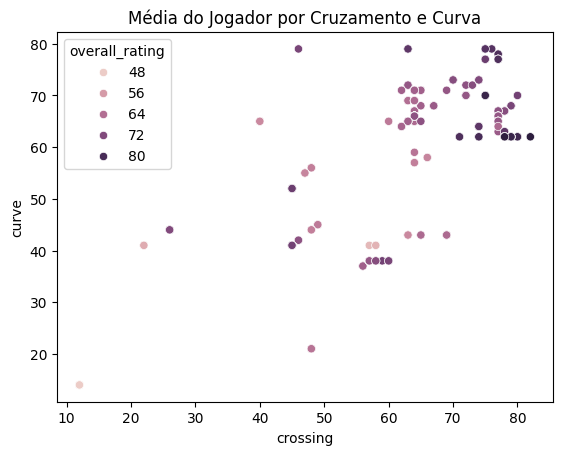

In [ ]:
sns.scatterplot( # Usando Seaborn para gerar um grafico de dispersão
    data=df_jogadores,
    x="crossing",
    y="curve",
    hue="overall_rating"
)

plt.title("Média do Jogador por Cruzamento e Curva")
plt.show()

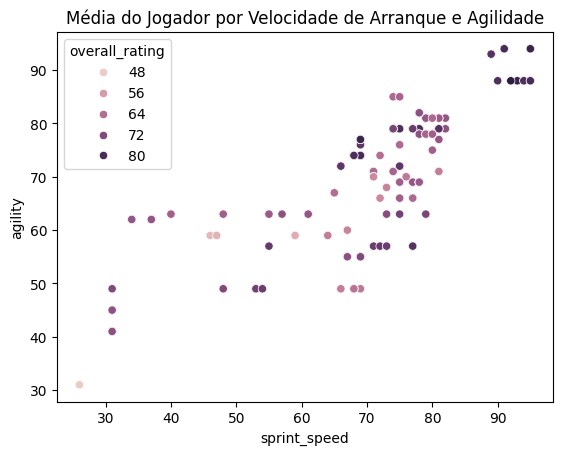

In [ ]:
sns.scatterplot( # Usando Seaborn para gerar um grafico de dispersão
    data=df_jogadores,
    x="sprint_speed",
    y="agility",
    hue="overall_rating"
)

plt.title("Média do Jogador por Velocidade de Arranque e Agilidade")
plt.show()

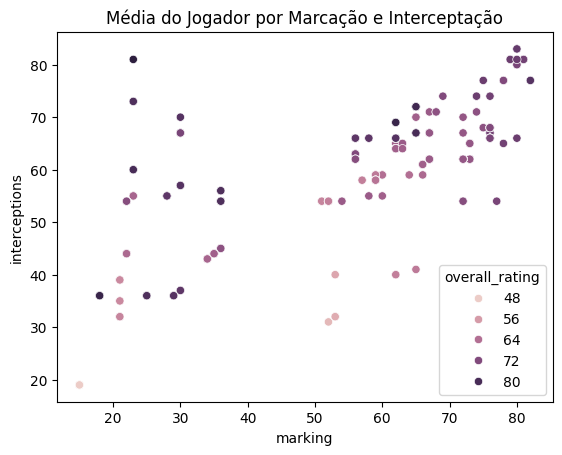

In [ ]:
sns.scatterplot( # Usando Seaborn para gerar um grafico de dispersão
    data=df_jogadores,
    x="marking",
    y="interceptions",
    hue="overall_rating"
)

plt.title("Média do Jogador por Marcação e Interceptação")
plt.show()

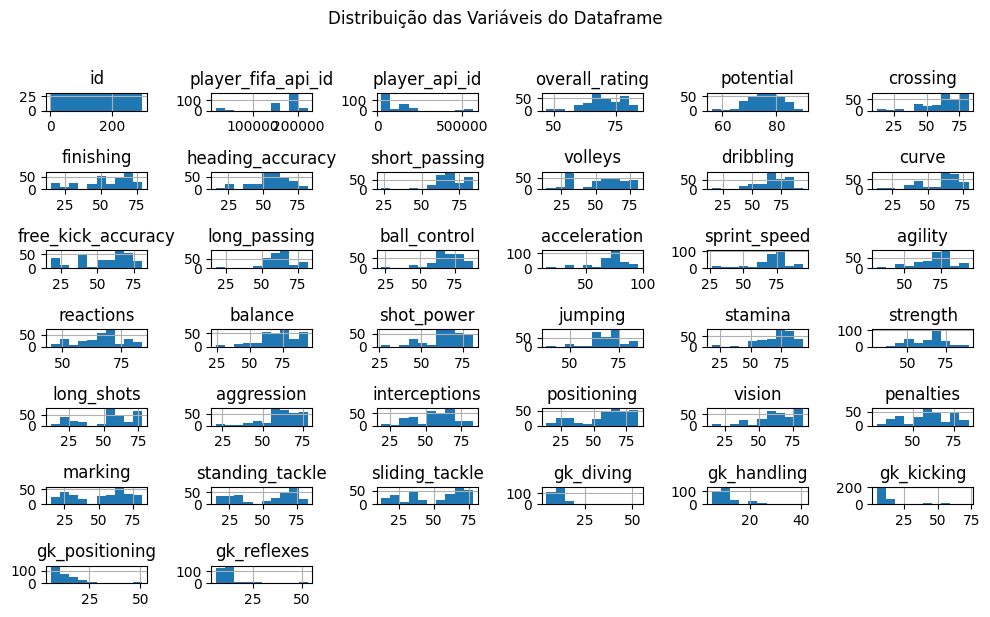

In [ ]:
df_jogadores[df_jogadores.columns].hist(figsize=(10, 6)) # Criando graficos de histograma
plt.suptitle("Distribuição das Variáveis do Dataframe", y=1.02)
plt.tight_layout()
plt.show()

## 2.3. Atribuindo os Valores de Treino e Teste

In [ ]:
x = df_jogadores[[ # Features
    'crossing',
    'finishing',
    'heading_accuracy',
    'short_passing',
    'volleys',
    'dribbling',
    'curve',
    'free_kick_accuracy',
    'long_passing',
    'ball_control',
    'acceleration',
    'sprint_speed',
    'agility',
    'reactions',
    'balance',
    'shot_power',
    'jumping',
    'stamina',
    'strength',
    'long_shots',
    'aggression',
    'interceptions',
    'positioning',
    'vision',
    'penalties',
    'marking',
    'standing_tackle',
    'sliding_tackle',
    'gk_diving',
    'gk_handling',
    'gk_kicking',
    'gk_positioning',
    'gk_reflexes'
]]
y = df_jogadores['overall_rating'] # Target
print("Formato de X: ", x.shape)
print("Formato de Y: ", y.shape)

Formato de X:  (300, 33)
Formato de Y:  (300,)


In [ ]:
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size = 0.2, random_state = 42) # Separando os valores para treinar e para testar
# Exibindo quanto foi para Treino e para teste
print("X_train: ", x_train.shape)
print("X_test: ", x_test.shape)
print("Y_train: ", y_train.shape)
print("Y_test: ", y_test.shape)

X_train:  (240, 33)
X_test:  (60, 33)
Y_train:  (240,)
Y_test:  (60,)


## 2.4. SVM

In [ ]:
pipeline = Pipeline([
    ("scaler", StandardScaler()), # Normalizando os valores
    ("svm", SVC()) # Usando o SVM
])
gridpr = {"svm__kernel":['linear', 'rbf', 'poly'],
          'svm__C':[1, 10, 100],
          'svm__gamma': [1, 0.1, 0.01]}
grid = GridSearchCV(
    pipeline,
    param_grid=gridpr,
    cv=5,
    scoring='accuracy'
)
grid.fit(x_train, y_train)
print("Melhores parametros: ", grid.best_params_)
print("Melhor Acuracia: ", grid.best_score_)
modelo=grid.best_estimator_
y_prever = modelo.predict(x_test)
print("Resultado esperado: ", list(y_test))
print("-------------------------------------------------------------")
print("Resultado obtido: ", (y_prever).tolist())
precisao = accuracy_score(y_test, y_prever) # Calculando a precisão do modelo linear
print("-------------------------------------------------------------")
print(f"Precisão do modelo no SVM linear: {precisao*100:.2f}%")

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


Melhores parametros:  {'svm__C': 1, 'svm__gamma': 1, 'svm__kernel': 'poly'}
Melhor Acuracia:  0.6458333333333334
Resultado esperado:  [72, 59, 79, 73, 60, 65, 64, 72, 74, 48, 61, 65, 65, 69, 69, 65, 78, 71, 78, 82, 70, 77, 71, 70, 75, 68, 81, 77, 79, 63, 70, 82, 51, 69, 68, 78, 73, 69, 70, 67, 72, 68, 79, 65, 68, 59, 62, 61, 75, 60, 69, 60, 63, 67, 77, 82, 74, 72, 67, 69]
-------------------------------------------------------------
Resultado obtido:  [72, 59, 79, 73, 60, 65, 64, 71, 74, 48, 61, 65, 65, 71, 69, 65, 78, 71, 78, 80, 69, 77, 71, 71, 76, 68, 81, 77, 79, 63, 70, 80, 52, 69, 68, 78, 73, 69, 71, 67, 72, 67, 79, 65, 67, 59, 62, 61, 68, 60, 69, 60, 63, 67, 77, 81, 74, 72, 68, 69]
-------------------------------------------------------------
Precisão do modelo no SVM linear: 76.67%


###2.4.1 Validação Cruzada

In [ ]:
validacao_cruzada = cross_val_score(modelo, x, y, cv = 5) # Realizando a validação cruzada
print("Precisão em cada verificação: ", validacao_cruzada)
print(f"Média: {validacao_cruzada.mean()*100:.2f}%")
print(f"Desvio Padrão: {validacao_cruzada.std()*100:.2f}%")

Precisão em cada verificação:  [0.46666667 0.58333333 0.7        0.66666667 0.33333333]
Média: 55.00%
Desvio Padrão: 13.50%


/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


###2.4.2 Matriz de Confusão

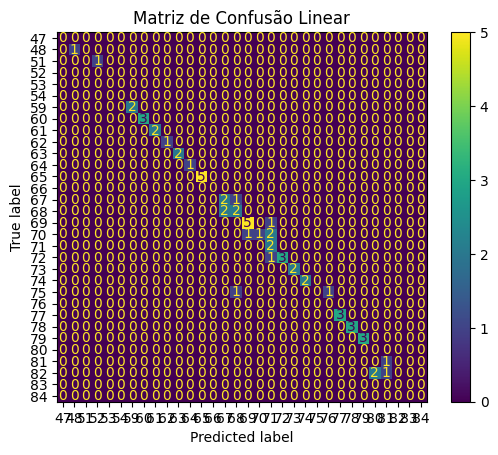

In [ ]:
label = sorted(df_jogadores['overall_rating'].unique())
matriz = confusion_matrix(y_test, y_prever, labels=label)
disp = ConfusionMatrixDisplay(confusion_matrix = matriz, display_labels=label)
disp.plot()
plt.title("Matriz de Confusão Linear")
plt.show()

### 2.4.3 Relatório

In [ ]:
print("Relatório de classificação do SVM: ")
print(classification_report(y_test, y_prever))

Relatório de classificação do SVM: 
              precision    recall  f1-score   support

          48       1.00      1.00      1.00         1
          51       0.00      0.00      0.00         1
          52       0.00      0.00      0.00         0
          59       1.00      1.00      1.00         2
          60       1.00      1.00      1.00         3
          61       1.00      1.00      1.00         2
          62       1.00      1.00      1.00         1
          63       1.00      1.00      1.00         2
          64       1.00      1.00      1.00         1
          65       1.00      1.00      1.00         5
          67       0.50      0.67      0.57         3
          68       0.50      0.50      0.50         4
          69       0.83      0.83      0.83         6
          70       1.00      0.25      0.40         4
          71       0.33      1.00      0.50         2
          72       1.00      0.75      0.86         4
          73       1.00      1.00      1.00  

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Recall is ill-defined and being set to 0.0 in labels with no true samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_

## 2.5 Arvore de Decisão, Floresta Aleatória e Boosting

### 2.5.1 Criando Modelos

In [ ]:
modelos = {
    'Árvore de Decisão': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}
for nome, md in modelos.items():
    md.fit(x_train, y_train)
    print(f'{nome}: treinado')

Árvore de Decisão: treinado
Random Forest: treinado
Gradient Boosting: treinado


### 2.5.2 Prevendo

In [ ]:
previsoes = {nome: md.predict(x_test) for nome, md in modelos.items()}
print('Valores reais:', y_test)
for nome, y_pred in previsoes.items():
    print(f'{nome}:', y_pred)

Valores reais: 203    72
266    59
152    79
9      73
233    60
226    65
196    64
109    72
5      74
175    48
237    61
57     65
218    65
45     69
182    69
221    65
289    78
211    71
148    78
165    82
78     70
113    77
249    71
250    70
104    75
42     68
281    81
295    77
157    79
238    63
17     70
164    82
33     51
24     69
215    68
119    78
7      73
90     69
46     70
73     67
93     72
76     68
286    79
60     65
77     68
63     59
234    62
229    61
111    75
231    60
180    69
144    60
239    63
75     67
297    77
278    82
97     74
92     72
192    67
25     69
Name: overall_rating, dtype: int64
Árvore de Decisão: [72 59 79 73 60 65 64 71 74 48 61 65 65 71 69 65 78 71 78 82 69 77 71 71
 76 68 81 77 79 63 70 82 52 69 68 78 73 69 71 67 72 69 79 65 69 59 62 61
 71 60 69 60 63 67 77 81 74 72 68 69]
Random Forest: [72 59 79 73 60 65 64 71 74 48 61 65 65 68 69 65 78 71 78 81 69 77 71 71
 76 68 81 77 79 63 70 81 52 69 68 78 73 69 71 67 72 69 79 6

### 2.5.3. Avaliando e Comparando

In [ ]:
label = sorted(df_jogadores['overall_rating'].unique())
resultados = []
for nome, y_pred in previsoes.items():
    acuracia = accuracy_score(y_test, y_pred)
    resultados.append({'Modelo': nome, 'Acurácia': acuracia})
    print(f'\n{nome} — Acurácia: {acuracia:.2%}')
    print(classification_report(y_test, y_pred, labels=label, target_names=[str(classe) for classe in label], zero_division=0))
pd.DataFrame(resultados).sort_values('Acurácia', ascending=False)


Árvore de Decisão — Acurácia: 80.00%
              precision    recall  f1-score   support

          47       0.00      0.00      0.00         0
          48       1.00      1.00      1.00         1
          51       0.00      0.00      0.00         1
          52       0.00      0.00      0.00         0
          53       0.00      0.00      0.00         0
          54       0.00      0.00      0.00         0
          59       1.00      1.00      1.00         2
          60       1.00      1.00      1.00         3
          61       1.00      1.00      1.00         2
          62       1.00      1.00      1.00         1
          63       1.00      1.00      1.00         2
          64       1.00      1.00      1.00         1
          65       1.00      1.00      1.00         5
          66       0.00      0.00      0.00         0
          67       1.00      0.67      0.80         3
          68       0.67      0.50      0.57         4
          69       0.62      0.83      0.71

,Modelo,Acurácia
0,Árvore de Decisão,0.800000
1,Random Forest,0.766667
2,Gradient Boosting,0.766667


### 2.5.4. Visualizando

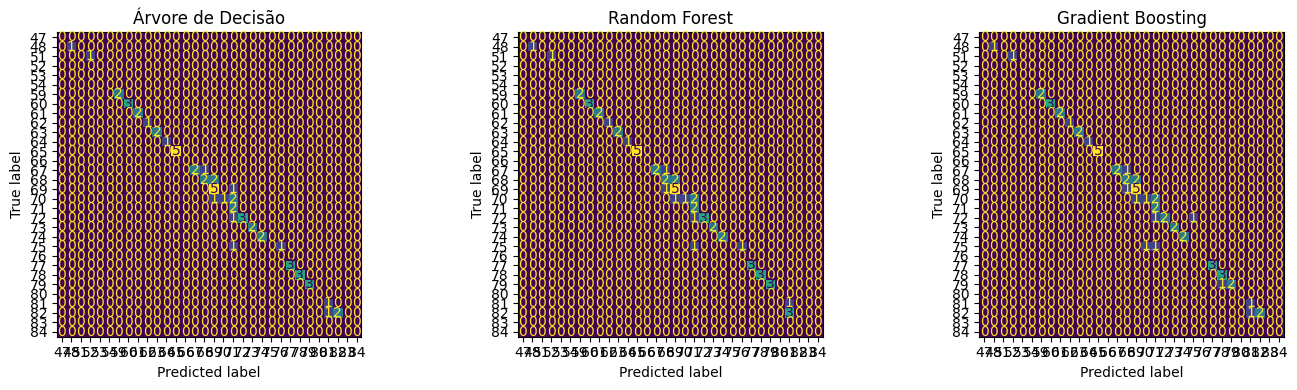

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (nome, y_pred) in zip(axes, previsoes.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=label, display_labels=label, ax=ax, colorbar=False)
    ax.set_title(nome)
plt.tight_layout()
plt.show()

## 2.6. Interpretando

Neste experimento, a Árvore de Decisão apresentou a maior acurácia no conjunto de teste, alcançando 80%. A Floresta Aleatória, o Gradient Boosting e o SVM obtiveram resultados de 76%.

No SVM, o melhor kernel selecionado pelo GridSearchCV foi o polinomial (`poly`). Entretanto, durante a validação cruzada, o modelo apresentou uma acurácia média de 55%, resultado inferior à acurácia de 76% obtida no conjunto de teste.

Essa diferença indica que o desempenho do modelo variou entre as avaliações realizadas. Portanto, é importante ter cautela ao interpretar o resultado obtido no teste, pois ele pode não representar o desempenho esperado em novos dados.

Comparando os quatro algoritmos, a Árvore de Decisão foi o modelo com maior acurácia no conjunto de teste. Porém, para determinar qual classificador apresenta o melhor desempenho de maneira mais consistente, também é necessário analisar as métricas de precisão, revocação, F1-score e as matrizes de confusão.

Conclui-se que, considerando apenas a acurácia do conjunto de teste, a Árvore de Decisão apresentou o melhor resultado neste experimento. Ainda assim, são necessárias avaliações adicionais para verificar a estabilidade dos resultados e a capacidade de generalização dos modelos.

#3. Prova A / Doenças Cardiacas

## 3.1. Download e criação do Dataframe

In [ ]:
import kagglehub #import que conecta com o kaggle, repositorio de datasets

In [ ]:
path = kagglehub.dataset_download("mfarhaannazirkhan/heart-dataset") #baixa um dataset no kaggle

Using Colab cache for faster access to the 'heart-dataset' dataset.


Nessa célula acima, foi feito o download do dataset solicitado usando a conexão com kaggle importada anteriormente e o caminho informado do dataset.

In [ ]:
df = pd.read_csv("/kaggle/input/heart-dataset/cleaned_merged_heart_dataset.csv") #salva em um dataframe os dados que foram baixados em um csv
df.head()

,age,sex,cp,trestbps,chol,fbs,restecg,thalachh,exang,oldpeak,slope,ca,thal,target
0,63,1,3,145,233,1,0,150,0,2.3,0,0,1,1
1,37,1,2,130,250,0,1,187,0,3.5,0,0,2,1
2,41,0,1,130,204,0,0,172,0,1.4,2,0,2,1
3,56,1,1,120,236,0,1,178,0,0.8,2,0,2,1
4,57,0,0,120,354,0,1,163,1,0.6,2,0,2,1


Aqui foi passado do arquivo .csv baixado na outra célula, os dados para o dataframe criado com Pandas.

## 3.2. Testes e visualizações

In [ ]:
df["target"].unique() #verificando quais dados estão presentes na coluna target

array([1, 0])

In [ ]:
df.isnull().sum() #verifica se há algum nulo

,0
age,0
sex,0
cp,0
trestbps,0
chol,0
fbs,0
restecg,0
thalachh,0
exang,0
oldpeak,0


Nas duas células anteriores, foi feito algumas consultas, primeiro em target, quais eram os dados lá presentes, se só haviam 0s e 1s. Já no segundo foi feito em todo dataset para ver se havia algum nulo.

<function matplotlib.pyplot.show(close=None, block=None)>

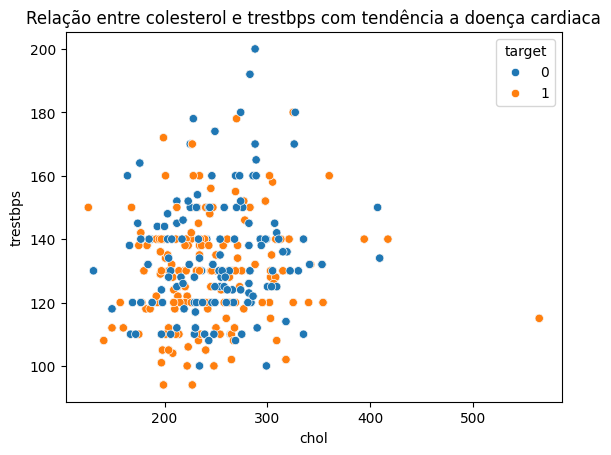

In [ ]:
sns.scatterplot(
    data= df,
    x= 'chol',
    y= 'trestbps',
    hue='target'
) #cria e passa os dados pro grafico
plt.title("Relação entre colesterol e trestbps com tendência a doença cardiaca") #cria o titulo
plt.show #mostra o grafico

No grafico de dispesão acima, é possivel ver as bolas laranjas que são que possui tendencia a doenca e a azul que não possui, onde elas estão posisionadas e qual a relação entre elas com colesterol(eixo x) e trestbps(eixo y), esse gráfico é interessante pois é possivel ver como esses dados mudam ou não a tendencia a doença.

<function matplotlib.pyplot.show(close=None, block=None)>

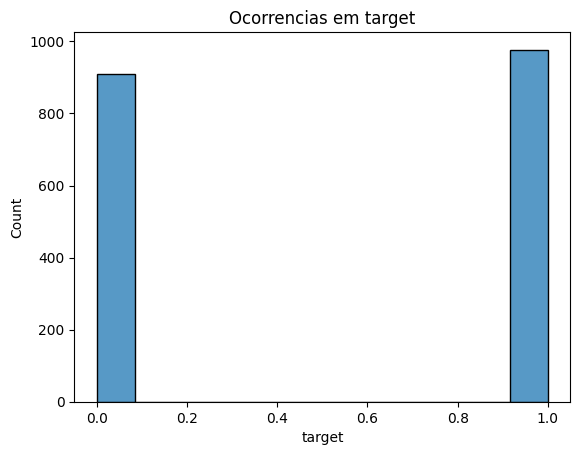

In [ ]:
sns.histplot(
    data=df,
    x="target"
) #cria o grafico e passa a coluna
plt.title("Ocorrencias em target")#cria o titulo
plt.show #mostra o grafico

Já esse grafico serve mais como o .unique(), vemos quais dados tem em target, só 0 e 1, mas também vemos a quantiadade de ocorrencias.

## 3.3. Separação dos dados

In [ ]:
x = df[['age',	'sex',	'cp',	'trestbps',	'chol',	'fbs',	'restecg',	'thalachh',	'exang',	'oldpeak',	'slope',	'ca',	'thal']] #as caractericas das pessoas do dataframe
y = df['target']#a variavel alvo, no caso o target com 0 para sem tendencia a doencça cardiaca e 1 para com.

Aqui iniciamos a separação de dados em x, com caractericas, ou seja tudo aquilo que foi infromado no dataframe e y com a variavel-alvo que é o que a maquina vai tentar prever.

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
) #aqui separamos em variaveis de treino e teste, passando x e y, passando o tamanho do teste que 20%, um valor pro random state e garantindo que y tenha sido separado de forma correta para não ter muito nem pouco de uma variavel
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape) #printei o shape das variaveis criadas, para verificar se elas possuiam tamanhos corretos.

(1510, 13)
(378, 13)
(1510,)
(378,)


Na célula acima, eu usei o train_test_split para separar os x e y de treino e de teste, defini 20% de teste, ou seja 80% de treino, esse valor foi o padrão ensinado em aula, para garaintir um melhor acuraria possivel.

##3.4 SVM

#### 3.4.1 Criação do modelo

In [ ]:
pipeline = Pipeline([('scaler', StandardScaler()), ('svm', SVC())]) # criação do pipeline

Na célula acima foi criado o pipeline que será usado no gridsearch e no modelo de aprendizagem, ele está vazio ainda pois terá os dados passados posteriormente.

#### 3.4.2.GridSearch

In [ ]:
parametros = {
    'svm__kernel':['linear', 'rbf', 'poly'],
    'svm__C':[1, 10, 100],
    'svm__gamma':['scale', 'auto', 1, 0.1, 0.01]
} #aqui criei um dicionario com todos os parametros que serão testados no GridSearch
grid = GridSearchCV(
    pipeline,
    parametros,
    cv=5,
    scoring='accuracy'
)#criando o gridsearch, passando o pipeline, os parametros, repetindo 5 vezes e pontuando por acuracia
grid.fit(x_train, y_train)
print("Os melhores parametros foram: ", grid.best_params_) #printa na tela os melhores parametros após rodar o gridsearch
print("O melhor score foi: ", grid.best_score_) #printa qual foi o melhor socre
modelo = grid.best_estimator_ #pega o melhor modelo em uma variavel

Os melhores parametros foram:  {'svm__C': 100, 'svm__gamma': 'scale', 'svm__kernel': 'poly'}
O melhor score foi:  0.9503311258278145


Acima fizemos o GridSearch, para testar todas combinações de parametros de forma automatica, afim de achar o melhor modelo. Primeiro criei um dicionario com todos parametros possiveis, depois o grid usando o GridSearch importado no comeco, treinei com dados x de treino e y treino, e por fim printei qual os melhores parametros, no caso: Poly, scale e 100, com um score de 95%, por fim peguei esse mehlro modelo em uma variavel para a proxima etapa.

#### 3.4.3. Uso do modelo e calculo da acuracia.

In [ ]:
ypred = modelo.predict(x_test) #faz as previsoes com o modelo passando os dados de teste.
acuracia = accuracy_score(ypred, y_test) #calcula a acuracia comparando o dado previsto com o real
print(f"A acuracia foi de {(acuracia*100):.2f}%") #printa pro usuario a acuracia

A acuracia foi de 95.24%


Nessa célula fiz a previsão de dados, usado um predict com o melhor modelo do gridsearch e passando o x teste. Depois calculei a acuracia usando o acuracy_score importado e comaprando os previstos com o real, por fim é printado essa acuracia.

#### 3.4.4. Validação Cruzada

In [ ]:
cruz = cross_val_score(modelo, x_test, y_test, cv=5) #criação de uma validação cruzada que repete 5 vezes com o modelo, passando x e y teste
print("Acuracias são: ", cruz) #printa as acuracias
print(f"Média: {(cruz.mean()*100):.2f}%")#calcula e printa a media
print(f"Desvio Padrão: {(cruz.std()*100):.2f}%")#calcula e printa o desvio padrão

Acuracias são:  [0.88157895 0.85526316 0.94736842 0.84       0.85333333]
Média: 87.55%
Desvio Padrão: 3.84%


Aqui eu fiz uma validação cruazada, que é basicamente reptir 5 vezes para garanitr que a acuracia anterior não fosse sorte, então roda 5 vezes diferentes com dados diferentes conseguindo acuracias diferentes, pegando a media e o desvio padrão.

#### 3.4.5 Métricas

In [ ]:
print(classification_report(y_test, ypred)) #printa uma tabelinha de classificação com a precisão, recall, f1score e support para saber qual a confiabilidade do modelo.

              precision    recall  f1-score   support

           0       0.98      0.92      0.95       182
           1       0.93      0.98      0.96       196

    accuracy                           0.95       378
   macro avg       0.95      0.95      0.95       378
weighted avg       0.95      0.95      0.95       378



Usando o classification report importado e passando y verdadeiro e previsto, é caluclado mais algumas métricas interessantes para saber o quão bom é esse modelo.

#### 3.4.6. Matriz de confusão

<function matplotlib.pyplot.show(close=None, block=None)>

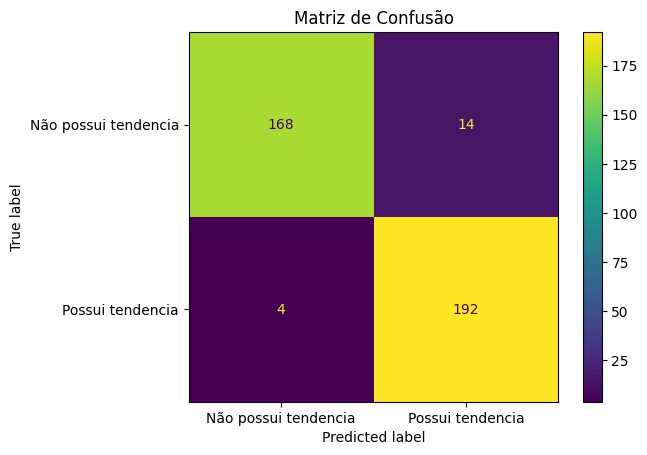

In [ ]:
matriz = confusion_matrix( y_test, ypred, labels= [0, 1]) #cria uma matriz, passando y verdadeiro e y previsto e o labels (0 e 1)
disp = ConfusionMatrixDisplay(matriz, display_labels=['Não possui tendencia', 'Possui tendencia']) #aqui é o que serás mostrado no grafico, a matriz da linha anterior, mais os laabels, como 0 e 1 fica muito confuso, eu troquei 0 para Não Possui e 1 para Possui.
disp.plot() #cria o grafico
plt.title("Matriz de Confusão") #cria o titulo
plt.show() #mostra na tela

Por ultimo criei uma matriz de confusão, checando quantos dados verdadeiros batem com os previstos, é possivel ver que a grande maioria bateu, com poucos erros.

## 3.5. Arvore de Decisão, Floresta Aleatória e Gradient Boosting

### 3.5.1 Criando os Modelos

In [ ]:
modelos = {
    'Árvore de Decisão': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}
for nome, md in modelos.items():
    md.fit(x_train, y_train)
    print(f'{nome}: treinado')

Árvore de Decisão: treinado
Random Forest: treinado
Gradient Boosting: treinado


Foram criados três classificadores: Árvore de Decisão, Floresta Aleatória (Random Forest) e Gradient Boosting. Cada modelo foi treinado utilizando os mesmos conjuntos de treinamento, permitindo comparar seus resultados nas mesmas condições.



### 3.5.2 Prevendo

In [ ]:
previsoes = {nome: md.predict(x_test) for nome, md in modelos.items()}
print('Valores reais:', y_test)
for nome, y_pred in previsoes.items():
    print(f'{nome}:', y_pred)

Valores reais: 1323    1
1579    1
1187    0
836     1
476     1
       ..
1181    0
1440    0
1131    1
200     0
1706    1
Name: target, Length: 378, dtype: int64
Árvore de Decisão: [1 0 0 1 1 1 1 1 1 1 1 1 0 0 0 0 0 1 0 1 0 1 0 1 1 1 0 1 1 0 0 1 0 1 0 0 1
 1 1 1 0 1 0 1 0 0 1 1 1 0 1 1 0 0 0 1 0 1 0 0 0 0 0 1 0 1 1 0 0 0 1 1 0 1
 1 1 1 0 1 1 1 1 1 1 0 1 0 1 0 0 1 0 0 0 0 1 1 1 1 0 0 0 0 1 1 0 1 0 1 0 1
 0 1 0 0 1 1 0 1 0 1 0 1 0 1 0 0 1 0 0 1 1 0 1 0 1 0 1 1 0 1 0 1 1 1 0 1 0
 1 0 0 1 1 0 0 1 0 0 0 1 0 1 0 0 1 0 1 0 0 0 1 1 0 0 0 0 0 0 1 0 1 0 0 1 1
 0 1 1 1 0 1 1 0 0 1 1 1 0 1 1 0 0 0 0 1 0 0 0 1 1 0 0 1 0 1 1 0 1 1 1 1 1
 1 1 0 1 0 0 1 1 1 0 1 1 0 0 0 1 0 1 1 1 1 0 0 0 0 1 1 1 1 1 1 1 0 0 1 0 1
 0 0 0 0 0 0 1 1 1 0 1 1 1 0 0 1 1 1 1 1 0 1 0 1 0 1 0 1 0 0 0 0 0 0 0 0 1
 1 0 1 1 0 1 1 0 0 0 1 1 1 0 1 0 0 1 0 0 1 1 1 0 1 0 1 1 0 0 0 1 1 0 0 1 1
 0 1 1 1 1 1 0 0 1 1 1 1 1 1 0 1 0 1 0 0 0 0 0 1 1 1 0 1 0 0 0 1 1 1 0 0 0
 0 0 0 0 1 1 0 1]
Random Forest: [1 1 0 1 1 1 1 1 1 1 1 1 0 0 0 0 

Após o treinamento, cada classificador foi utilizado para prever as classes do conjunto de teste. As previsões foram armazenadas no dicionário previsoes, facilitando a avaliação e a comparação entre os modelos.

### 3.5.3 Avaliando e Comparando

In [ ]:
label=[0,1]
resultados = []
for nome, y_pred in previsoes.items():
    acuracia = accuracy_score(y_test, y_pred)
    resultados.append({'Modelo': nome, 'Acurácia': acuracia})
    print(f'\n{nome} — Acurácia: {acuracia:.2%}')
    print(classification_report(y_test, y_pred, labels=label, target_names=[str(classe) for classe in label], zero_division=0))
pd.DataFrame(resultados).sort_values('Acurácia', ascending=False)


Árvore de Decisão — Acurácia: 97.62%
              precision    recall  f1-score   support

           0       0.97      0.98      0.98       182
           1       0.98      0.97      0.98       196

    accuracy                           0.98       378
   macro avg       0.98      0.98      0.98       378
weighted avg       0.98      0.98      0.98       378


Random Forest — Acurácia: 97.88%
              precision    recall  f1-score   support

           0       0.98      0.97      0.98       182
           1       0.97      0.98      0.98       196

    accuracy                           0.98       378
   macro avg       0.98      0.98      0.98       378
weighted avg       0.98      0.98      0.98       378


Gradient Boosting — Acurácia: 93.39%
              precision    recall  f1-score   support

           0       0.93      0.93      0.93       182
           1       0.94      0.93      0.94       196

    accuracy                           0.93       378
   macro avg      

,Modelo,Acurácia
1,Random Forest,0.978836
0,Árvore de Decisão,0.976190
2,Gradient Boosting,0.933862


Nesta etapa, foi calculada a acurácia de cada classificador e gerado o relatório de classificação com precisão, recall, F1-score e suporte. Os resultados foram organizados em uma tabela ordenada pela acurácia, facilitando a comparação do desempenho dos modelos.

### 3.5.4. Vizualizando

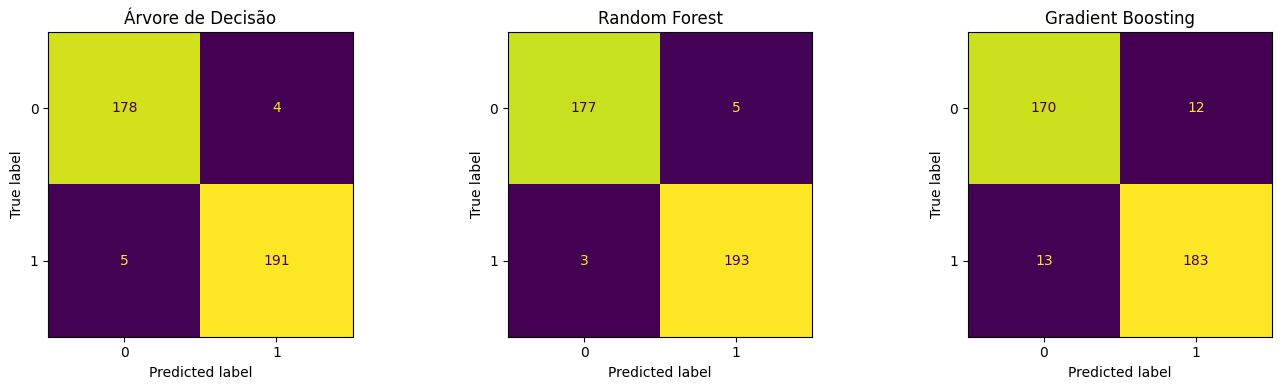

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (nome, y_pred) in zip(axes, previsoes.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=label, display_labels=label, ax=ax, colorbar=False)
    ax.set_title(nome)
plt.tight_layout()
plt.show()

Foram construídas matrizes de confusão para os três classificadores, organizadas lado a lado para facilitar a comparação. Essa visualização permite verificar como cada modelo classificou os registros de teste e quais erros ocorreram em cada classe.

## 3.6 Interpretando

Após realizar os testes, foi possível comparar o desempenho de diferentes modelos para prever a tendência à doença cardíaca. A Árvore de Decisão e a Floresta Aleatória alcançaram uma acurácia de 97%, enquanto o Gradient Boosting obteve 93%.

Esses resultados indicam que, neste experimento, a Árvore de Decisão e a Floresta Aleatória apresentaram o melhor desempenho em relação à acurácia no conjunto de teste, com resultados superiores aos do Gradient Boosting.

Ao comparar esses resultados com o SVM, que alcançou uma acurácia de 95,24% no conjunto de teste, observa-se que a Árvore de Decisão e a Floresta Aleatória tiveram resultados ligeiramente melhores. Entretanto, o SVM também apresentou um bom desempenho, com um melhor score de aproximadamente 95% durante a busca de hiperparâmetros pelo GridSearchCV.

Portanto, considerando apenas a acurácia obtida no conjunto de teste, a Árvore de Decisão e a Floresta Aleatória foram os modelos com melhores resultados neste experimento. Para uma comparação mais completa, também é importante analisar as métricas de precisão, recall e F1-score, além das matrizes de confusão, para verificar os tipos de erro cometidos por cada modelo.

# #### Imports

In [ ]:
import seaborn as sns #import necessario para criação de graficos
import matplotlib.pyplot as plt #tambem necessario para criação de graficos
import pandas as pd #necessario para criacao de dataframe
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV #imports de sklearn que vao separar os dados entre treino e teste, validação cruzada e gridsearch
from sklearn.preprocessing import StandardScaler #import para padronização de dados
from sklearn.pipeline import Pipeline #import do modelo pipeline que sera usado para criar o svm
from sklearn.svm import SVC #import do modelo svc
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, ConfusionMatrixDisplay #import das metricas de classificacao que serão usadas depois

Para inciar, foi realizado todos imports de bibliotecas necessarios para a execução dessa tarefa, desde a criação de gráficos, quanto a dataframe e modelos de sklearn, até a criação de uma conexão com o kaggle.

#4. FishMorph

## 4.1. Download e criação do Dataframe

In [ ]:
import kagglehub #import que conecta com o kaggle, repositorio de datasets

In [ ]:
path = kagglehub.dataset_download("menegidio/fishmorph-dataset") #baixa um dataset no kaggle

Using Colab cache for faster access to the 'fishmorph-dataset' dataset.


In [ ]:
df = pd.read_csv("/kaggle/input/fishmorph-dataset/FISHMORPH_Family_Dataset.csv") #salva em um dataframe os dados que foram baixados em um csv
df.head()

,MBl,BEl,VEp,REs,OGp,RMl,BLs,PFv,PFs,CPt,Family
0,130.0,4.579113,0.622642,0.375019,0.622642,0.868659,0.484981,0.273585,0.144108,3.348991,Cyprinidae
1,11.5,2.796068,0.650700,0.353780,0.509800,0.411157,0.722461,0.330169,0.221095,2.525592,Cichlidae
2,6.6,4.564329,0.518187,0.312002,0.203985,0.413221,0.591495,0.105517,0.188193,2.104580,Cyprinidae
3,10.9,4.390422,0.548247,0.244804,0.168959,0.324728,0.642991,0.097450,0.193049,1.787062,Cyprinidae
4,18.9,4.410271,0.542353,0.292058,0.183790,0.398567,0.685672,0.087643,0.170648,2.968906,Cyprinidae


O dataset FishMorph foi baixado utilizando a biblioteca KaggleHub, que permite acessar conjuntos de dados disponibilizados no Kaggle. Em seguida, o arquivo CSV foi carregado em um DataFrame utilizando a biblioteca Pandas, permitindo visualizar e manipular os dados.

## 4.2. Testes e visualizações

In [ ]:
df["Family"].unique()

array(['Cyprinidae', 'Cichlidae', 'Anostomidae', 'Abyssocottidae',
       'Centrarchidae', 'Loricariidae', 'Characidae', 'Mochokidae',
       'Nemacheilidae', 'Doradidae', 'Gobiidae', 'Sparidae',
       'Trichomycteridae', 'Cobitidae', 'Heptapteridae',
       'Acestrorhynchidae', 'Soleidae', 'Achiridae', 'Acipenseridae',
       'Akysidae', 'Apteronotidae', 'Nandidae', 'Auchenipteridae',
       'Mugilidae', 'Pimelodidae', 'Schilbeidae', 'Alestidae',
       'Poeciliidae', 'Goodeidae', 'Eleotridae', 'Clupeidae',
       'Aspredinidae', 'Bagridae', 'Engraulidae', 'Ambassidae',
       'Amblycipitidae', 'Ictaluridae', 'Amiidae', 'Percidae',
       'Crenuchidae', 'Terapontidae', 'Amphiliidae', 'Anabantidae',
       'Anablepidae', 'Rivulidae', 'Ariidae', 'Anguillidae',
       'Balitoridae', 'Plotosidae', 'Hemiodontidae', 'Parodontidae',
       'Gasterosteidae', 'Cyprinodontidae', 'Aphredoderidae',
       'Aplocheilidae', 'Galaxiidae', 'Sciaenidae', 'Arapaimidae',
       'Sternopygidae', 'Gobies

In [ ]:
df.isnull().sum() #verifica se há algum nulo

,0
MBl,0
BEl,0
VEp,0
REs,0
OGp,0
RMl,0
BLs,0
PFv,0
PFs,0
CPt,0


Nesta etapa, foram realizadas algumas consultas iniciais para conhecer melhor o conjunto de dados. Primeiro, foram identificadas as famílias de peixes presentes na coluna Family, que representa a variável-alvo do problema. Depois, foi verificada a quantidade de valores ausentes em cada coluna, a fim de identificar possíveis dados faltantes.

## 4.3. Separação dos dados

In [ ]:
x = df[['MBl',	'BEl',	'VEp',	'REs',	'OGp']]
y = df['Family']

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42
) #aqui separamos em variaveis de treino e teste, passando x e y, passando o tamanho do teste que 20%, um valor pro random state e garantindo que y tenha sido separado de forma correta para não ter muito nem pouco de uma variavel
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape) #printei o shape das variaveis criadas, para verificar se elas possuiam tamanhos corretos.

(6673, 5)
(1669, 5)
(6673,)
(1669,)


Nesta etapa, os dados foram separados em duas partes: x, contendo as características morfológicas utilizadas pelos modelos, e y, contendo a família do peixe que o modelo deverá prever.

Em seguida, foi utilizada a função train_test_split para dividir os dados em conjuntos de treinamento e teste. Foram destinados 80% dos dados ao treinamento e 20% aos testes, utilizando random_state=42 para tornar a divisão reproduzível. A separação permite treinar os modelos com uma parte dos dados e avaliar seu desempenho em registros que não foram utilizados diretamente no treinamento.

##4.4 SVM

#### 4.4.1 Criação do modelo

In [ ]:
pipeline = Pipeline([('scaler', StandardScaler()), ('svm', SVC())]) # criação do pipeline

Nesta etapa, foi criado um pipeline contendo o StandardScaler e o classificador SVM. O escalonador padroniza as características numéricas, colocando-as em escalas comparáveis, enquanto o SVM é responsável por aprender a classificar os peixes de acordo com suas características morfológicas.

O pipeline reúne essas etapas em um único objeto, facilitando o treinamento e a busca pelos melhores hiperparâmetros.

#### 4.4.2.GridSearch

In [ ]:
parametros = {
    'svm__kernel':['linear', 'rbf', 'poly'],
    'svm__C':[1, 10, 100],
    'svm__gamma':['auto', 'scale', 1, 0.1, 0.01]
} #aqui criei um dicionario com todos os parametros que serão testados no GridSearch
grid = GridSearchCV(
    pipeline,
    parametros,
    cv=5,
    scoring='accuracy'
)#criando o gridsearch, passando o pipeline, os parametros, repetindo 5 vezes e pontuando por acuracia
grid.fit(x_train, y_train)
print("Os melhores parametros foram: ", grid.best_params_) #printa na tela os melhores parametros após rodar o gridsearch
print("O melhor score foi: ", grid.best_score_) #printa qual foi o melhor socre
modelo = grid.best_estimator_ #pega o melhor modelo em uma variavel

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


Os melhores parametros foram:  {'svm__C': 1, 'svm__gamma': 'auto', 'svm__kernel': 'rbf'}
O melhor score foi:  0.4377338297143563


Foi utilizado o GridSearchCV para testar diferentes combinações de hiperparâmetros do SVM, incluindo os kernels linear, rbf e poly, diferentes valores de C e diferentes configurações de gamma.

A busca foi realizada com validação cruzada de cinco divisões e utilizando a acurácia como métrica de avaliação. Ao final, foram exibidos os melhores parâmetros encontrados e a melhor acurácia média obtida durante a busca. O melhor estimador foi armazenado na variável modelo para ser utilizado nas próximas etapas.

#### 4.4.3. Uso do modelo e calculo da acuracia.

In [ ]:
ypred = modelo.predict(x_test) #faz as previsoes com o modelo passando os dados de teste.
acuracia = accuracy_score(ypred, y_test) #calcula a acuracia comparando o dado previsto com o real
print(f"A acuracia foi de {(acuracia*100):.2f}%") #printa pro usuario a acuracia

A acuracia foi de 42.72%


Após selecionar o melhor modelo, foram realizadas previsões utilizando os dados de teste. Em seguida, a função accuracy_score foi utilizada para comparar as famílias previstas pelo modelo com as famílias reais, calculando a acurácia do SVM no conjunto de teste.

Essa métrica indica a proporção de previsões corretas em relação ao total de amostras avaliadas.

#### 4.4.4. Validação Cruzada

In [ ]:
cruz = cross_val_score(modelo, x_test, y_test, cv=5) #criação de uma validação cruzada que repete 5 vezes com o modelo, passando x e y teste
print("Acuracias são: ", cruz) #printa as acuracias
print(f"Média: {(cruz.mean()*100):.2f}%")#calcula e printa a media
print(f"Desvio Padrão: {(cruz.std()*100):.2f}%")#calcula e printa o desvio padrão

/usr/local/lib/python3.13/dist-packages/sklearn/model_selection/_split.py:805: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


Acuracias são:  [0.4011976  0.39820359 0.38922156 0.36227545 0.3963964 ]
Média: 38.95%
Desvio Padrão: 1.42%


Nesta etapa, foi realizada a validação cruzada com cinco divisões para avaliar o desempenho do modelo em diferentes partições dos dados de treinamento. Foram calculadas as acurácias de cada divisão, a média e o desvio padrão.

A média permite observar o desempenho médio obtido nas divisões, enquanto o desvio padrão ajuda a verificar a variação entre os resultados. Essa análise complementa a avaliação realizada no conjunto de teste.



#### 4.4.5 Métricas

In [ ]:
print(classification_report(y_test, ypred)) #printa uma tabelinha de classificação com a precisão, recall, f1score e support para saber qual a confiabilidade do modelo.

                     precision    recall  f1-score   support

     Abyssocottidae       0.00      0.00      0.00         3
  Acestrorhynchidae       0.00      0.00      0.00         3
          Achiridae       0.00      0.00      0.00         3
      Acipenseridae       1.00      0.80      0.89         5
   Adrianichthyidae       0.00      0.00      0.00         1
           Akysidae       0.00      0.00      0.00         1
          Alestidae       0.00      0.00      0.00        18
         Ambassidae       0.00      0.00      0.00         4
     Amblycipitidae       0.00      0.00      0.00         1
       Ambylopsidae       0.00      0.00      0.00         1
        Amphiliidae       1.00      0.12      0.22         8
        Anabantidae       0.00      0.00      0.00         6
        Anguillidae       0.67      1.00      0.80         2
        Anostomidae       0.00      0.00      0.00        24
      Aplocheilidae       0.00      0.00      0.00        16
      Apteronotidae    

/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


Foi utilizado o classification_report para obter métricas adicionais sobre o desempenho do SVM. O relatório apresenta precisão, recall, F1-score e suporte para cada família de peixes.

Essas métricas permitem analisar o desempenho do classificador por classe, oferecendo informações que não são apresentadas apenas pela acurácia geral.

#### 4.4.6. Matriz de confusão

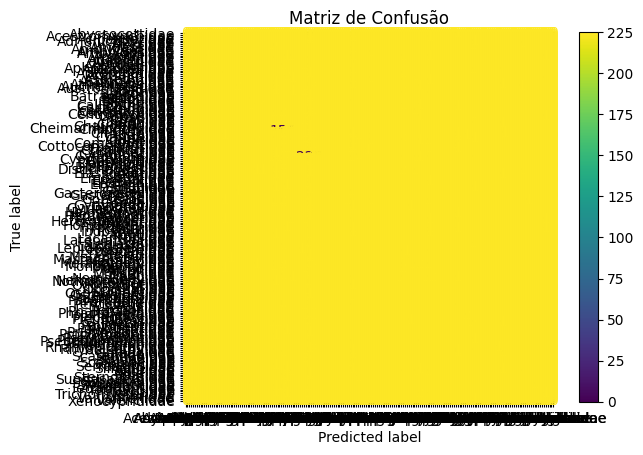

In [ ]:
label = sorted(df["Family"].unique())
matriz = confusion_matrix( y_test, ypred, labels= label) #cria uma matriz, passando y verdadeiro e y previsto e o labels
disp = ConfusionMatrixDisplay(matriz, display_labels=label) #aqui é o que serás mostrado no grafico, a matriz da linha anterior, mais os labels.
disp.plot() #cria o grafico
plt.title("Matriz de Confusão") #cria o titulo
plt.show() #mostra na tela

Por fim, foi construída a matriz de confusão do SVM, comparando as famílias reais com as famílias previstas pelo modelo. A diagonal principal representa as classificações corretas, enquanto os valores fora dela indicam os casos em que uma família foi confundida com outra.

Essa visualização ajuda a identificar quais famílias foram classificadas corretamente e em quais ocorreram mais erros.

## 4.5. Arvore de Decisão, Floresta Aleatória e Gradient Boosting

### 4.5.1 Criando os Modelos

In [ ]:
modelos = {
    'Árvore de Decisão': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}
for nome, md in modelos.items():
    md.fit(x_train, y_train)
    print(f'{nome}: treinado')

Árvore de Decisão: treinado
Random Forest: treinado
Gradient Boosting: treinado


Foram criados três classificadores: Árvore de Decisão, Floresta Aleatória (Random Forest) e Gradient Boosting. Cada modelo foi treinado utilizando os mesmos conjuntos de treinamento, permitindo comparar seus resultados nas mesmas condições.



### 4.5.2 Prevendo

In [ ]:
previsoes = {nome: md.predict(x_test) for nome, md in modelos.items()}
print('Valores reais:', y_test)
for nome, y_pred in previsoes.items():
    print(f'{nome}:', y_pred)

Valores reais: 7023        Gobiidae
5201    Catostomidae
4280      Cyprinidae
940       Cyprinidae
5364         Ariidae
            ...     
1174      Characidae
6211        Percidae
6041      Cyprinidae
2249    Loricariidae
5507      Cyprinidae
Name: Family, Length: 1669, dtype: object
Árvore de Decisão: ['Cyprinidae' 'Mochokidae' 'Cyprinidae' ... 'Anostomidae' 'Cobitidae'
 'Cobitidae']
Random Forest: ['Cichlidae' 'Cyprinidae' 'Cyprinidae' ... 'Cyprinidae' 'Loricariidae'
 'Cyprinidae']
Gradient Boosting: ['Cichlidae' 'Bagridae' 'Cyprinidae' ... 'Cyprinidae' 'Loricariidae'
 'Cyprinidae']


Após o treinamento, cada classificador foi utilizado para prever as classes do conjunto de teste. As previsões foram armazenadas no dicionário previsoes, facilitando a avaliação e a comparação entre os modelos.

### 4.5.3 Avaliando e Comparando

In [ ]:
resultados = []
for nome, y_pred in previsoes.items():
    acuracia = accuracy_score(y_test, y_pred)
    resultados.append({'Modelo': nome, 'Acurácia': acuracia})
    print(f'\n{nome} — Acurácia: {acuracia:.2%}')
    print(classification_report(y_test, y_pred, labels=label, target_names=[str(classe) for classe in label], zero_division=0))
pd.DataFrame(resultados).sort_values('Acurácia', ascending=False)


Árvore de Decisão — Acurácia: 31.16%
                     precision    recall  f1-score   support

     Abyssocottidae       0.00      0.00      0.00         3
  Acestrorhynchidae       0.00      0.00      0.00         3
          Achiridae       0.00      0.00      0.00         3
      Acipenseridae       1.00      0.60      0.75         5
   Adrianichthyidae       0.00      0.00      0.00         1
           Akysidae       0.00      0.00      0.00         1
          Alestidae       0.00      0.00      0.00        18
         Ambassidae       0.00      0.00      0.00         4
     Amblycipitidae       0.00      0.00      0.00         1
       Amblyopsidae       0.00      0.00      0.00         0
       Ambylopsidae       0.00      0.00      0.00         1
            Amiidae       0.00      0.00      0.00         0
        Amphiliidae       0.43      0.38      0.40         8
        Anabantidae       0.33      0.17      0.22         6
        Anablepidae       0.00      0.00      

,Modelo,Acurácia
1,Random Forest,0.438586
2,Gradient Boosting,0.378071
0,Árvore de Decisão,0.311564


Nesta etapa, foi calculada a acurácia de cada classificador e gerado o relatório de classificação com precisão, recall, F1-score e suporte. Os resultados foram organizados em uma tabela ordenada pela acurácia, facilitando a comparação do desempenho dos modelos.

### 4.5.4. Vizualizando

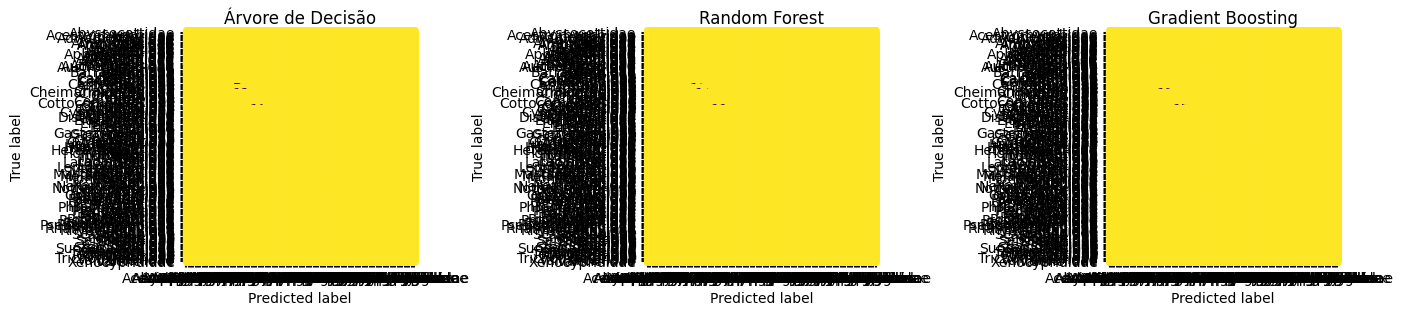

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (nome, y_pred) in zip(axes, previsoes.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=label, display_labels=label, ax=ax, colorbar=False)
    ax.set_title(nome)
plt.tight_layout()
plt.show()

Foram construídas matrizes de confusão para os três classificadores, organizadas lado a lado para facilitar a comparação. Essa visualização permite verificar como cada modelo classificou os registros de teste e quais erros ocorreram em cada classe.

## 4.6 Interpretando

Neste experimento, foram comparados quatro algoritmos de classificação para prever a família dos peixes a partir de suas características morfológicas: SVM, Árvore de Decisão, Random Forest e Gradient Boosting.

O SVM foi avaliado utilizando o GridSearchCV para selecionar os melhores hiperparâmetros. Em seguida, seu desempenho foi analisado por meio da acurácia, da validação cruzada, do relatório de classificação e da matriz de confusão.

Na comparação dos modelos, a Árvore de Decisão obteve acurácia de 31%, a Random Forest obteve 43% e o Gradient Boosting obteve 37% no conjunto de teste. O SVM alcançou 42% de acurácia no mesmo conjunto.

Considerando os resultados obtidos, o modelo com maior acurácia no conjunto de teste foi a Floresta Aleatória. Entretanto, a acurácia, isoladamente, não permite avaliar completamente a capacidade dos classificadores de distinguir todas as famílias. Por isso, também é importante analisar as métricas de precisão, recall e F1-score, bem como as matrizes de confusão.

Conclui-se que os modelos avaliados podem ser comparados quanto à sua capacidade de classificar as famílias dos peixes com base nas características fornecidas. A escolha do modelo mais adequado deve considerar não apenas a acurácia geral, mas também seu desempenho nas diferentes classes.

#5. Prova B / Nivel de Estresse de Alunos

## 5.1. Download e criação do Dataframe

In [ ]:
import kagglehub
path = kagglehub.dataset_download("rxnach/student-stress-factors-a-comprehensive-analysis")

Using Colab cache for faster access to the 'student-stress-factors-a-comprehensive-analysis' dataset.


In [ ]:
df = pd.read_csv("/kaggle/input/student-stress-factors-a-comprehensive-analysis/StressLevelDataset.csv") #salva em um dataframe os dados que foram baixados em um csv
df.head()

,anxiety_level,self_esteem,mental_health_history,depression,headache,blood_pressure,sleep_quality,breathing_problem,noise_level,living_conditions,...,basic_needs,academic_performance,study_load,teacher_student_relationship,future_career_concerns,social_support,peer_pressure,extracurricular_activities,bullying,stress_level
0,14,20,0,11,2,1,2,4,2,3,...,2,3,2,3,3,2,3,3,2,1
1,15,8,1,15,5,3,1,4,3,1,...,2,1,4,1,5,1,4,5,5,2
2,12,18,1,14,2,1,2,2,2,2,...,2,2,3,3,2,2,3,2,2,1
3,16,12,1,15,4,3,1,3,4,2,...,2,2,4,1,4,1,4,4,5,2
4,16,28,0,7,2,3,5,1,3,2,...,3,4,3,1,2,1,5,0,5,1


O dataset foi baixado do Kaggle utilizando a biblioteca kagglehub. Em seguida, o arquivo CSV foi carregado em um DataFrame do Pandas, permitindo visualizar e manipular os dados que serão utilizados para classificar o nível de estresse dos alunos.

A função head() foi utilizada para exibir as primeiras linhas do DataFrame e observar a estrutura das informações disponíveis.

## 5.2. Testes e visualizações

In [ ]:
df.isnull().sum() #verifica se há algum nulo

,0
anxiety_level,0
self_esteem,0
mental_health_history,0
depression,0
headache,0
blood_pressure,0
sleep_quality,0
breathing_problem,0
noise_level,0
living_conditions,0


Foi utilizada a função isnull().sum() para verificar a quantidade de valores ausentes em cada coluna do dataset. Essa análise ajuda a identificar possíveis problemas nos dados antes de iniciar o treinamento dos modelos.

## 5.3. Separação dos dados

In [ ]:
x = df[['anxiety_level',	'depression',	'headache',	'future_career_concerns',	'bullying',	'sleep_quality']]
y = df['stress_level']

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
    stratify = y
) #aqui separamos em variaveis de treino e teste, passando x e y, passando o tamanho do teste que 20%, um valor pro random state e garantindo que y tenha sido separado de forma correta para não ter muito nem pouco de uma variavel
print(x_train.shape)
print(x_test.shape)
print(y_train.shape)
print(y_test.shape) #printei o shape das variaveis criadas, para verificar se elas possuiam tamanhos corretos.

(880, 6)
(220, 6)
(880,)
(220,)


A variável x foi definida com seis características selecionadas do dataset: nível de ansiedade, depressão, dores de cabeça, preocupações com a carreira futura, bullying e qualidade do sono. Essas informações serão utilizadas como entradas dos modelos.

A variável y corresponde à coluna stress_level, que representa a variável-alvo que o modelo deverá prever. A tarefa consiste em classificar os registros nas três classes de nível de estresse, identificadas pelos valores 0, 1 e 2.

Em seguida, os dados foram divididos em conjuntos de treinamento e teste, utilizando 80% dos registros para treinamento e 20% para teste. O parâmetro random_state=42 permite reproduzir a mesma divisão, enquanto stratify=y busca preservar a proporção das classes nos dois conjuntos.

As dimensões dos conjuntos foram exibidas com shape para conferir a quantidade de registros após a divisão.

##5.4 SVM

##### 5.4.1 Criação do modelo

In [ ]:
pipeline = Pipeline([('scaler', StandardScaler()), ('svm', SVC())]) # criação do pipeline

Foi criado um pipeline contendo o StandardScaler e o classificador SVC. O padronizador ajusta a escala das características utilizadas, enquanto o SVM realiza a classificação dos níveis de estresse. O pipeline organiza essas etapas e permite que a padronização seja aplicada corretamente durante a busca pelos melhores hiperparâmetros.

##### 5.4.2.GridSearch

In [ ]:
parametros = {
    'svm__kernel':['linear', 'rbf', 'poly'],
    'svm__C':[1, 10, 100],
    'svm__gamma':['scale', 'auto', 1, 0.1, 0.01]
} #aqui criei um dicionario com todos os parametros que serão testados no GridSearch
grid = GridSearchCV(
    pipeline,
    parametros,
    cv=5,
    scoring='accuracy'
)#criando o gridsearch, passando o pipeline, os parametros, repetindo 5 vezes e pontuando por acuracia
grid.fit(x_train, y_train)
print("Os melhores parametros foram: ", grid.best_params_) #printa na tela os melhores parametros após rodar o gridsearch
print("O melhor score foi: ", grid.best_score_) #printa qual foi o melhor socre
modelo = grid.best_estimator_ #pega o melhor modelo em uma variavel

Os melhores parametros foram:  {'svm__C': 1, 'svm__gamma': 1, 'svm__kernel': 'poly'}
O melhor score foi:  0.8897727272727274


Foi definido um conjunto de hiperparâmetros para testar diferentes kernels (linear, rbf e poly), valores de C e valores de gamma. O GridSearchCV avaliou as combinações utilizando validação cruzada com cinco divisões e a acurácia como métrica de seleção.

Após o treinamento com os dados de treinamento, foram exibidos os melhores hiperparâmetros e a melhor pontuação média encontrada. O melhor estimador foi armazenado na variável modelo para ser utilizado nas etapas seguintes.

##### 5.4.3. Uso do modelo e calculo da acuracia.

In [ ]:
ypred = modelo.predict(x_test) #faz as previsoes com o modelo passando os dados de teste.
acuracia = accuracy_score(ypred, y_test) #calcula a acuracia comparando o dado previsto com o real
print(f"A acuracia foi de {(acuracia*100):.2f}%") #printa pro usuario a acuracia

A acuracia foi de 88.18%


O melhor modelo selecionado pelo GridSearchCV foi utilizado para prever as classes do conjunto de teste. Em seguida, a função accuracy_score comparou as previsões com os valores reais, calculando a proporção de classificações corretas.

Essa métrica fornece uma visão geral do desempenho do modelo no conjunto de teste, mas deve ser analisada em conjunto com outras métricas, principalmente porque o problema possui três classes.

##### 5.4.4. Validação Cruzada

In [ ]:
cruz = cross_val_score(modelo, x_test, y_test, cv=5) #criação de uma validação cruzada que repete 5 vezes com o modelo, passando x e y teste
print("Acuracias são: ", cruz) #printa as acuracias
print(f"Média: {(cruz.mean()*100):.2f}%")#calcula e printa a media
print(f"Desvio Padrão: {(cruz.std()*100):.2f}%")#calcula e printa o desvio padrão

Acuracias são:  [0.86363636 0.93181818 0.84090909 0.86363636 0.81818182]
Média: 86.36%
Desvio Padrão: 3.80%


A validação cruzada permite avaliar como o desempenho do modelo varia entre diferentes divisões dos dados. A função cross_val_score calcula uma pontuação para cada divisão, possibilitando observar a média e o desvio padrão das acurácias.

Para essa avaliação, é preferível utilizar os dados de treinamento, mantendo o conjunto de teste reservado para a avaliação final do modelo. Como os hiperparâmetros já foram selecionados pelo GridSearchCV, uma avaliação rigorosa da generalização deve considerar também esse processo de seleção.

##### 5.4.5 Métricas

In [ ]:
print(classification_report(y_test, ypred)) #printa uma tabelinha de classificação com a precisão, recall, f1score e support para saber qual a confiabilidade do modelo.

              precision    recall  f1-score   support

           0       0.87      0.88      0.87        74
           1       0.87      0.92      0.89        72
           2       0.91      0.85      0.88        74

    accuracy                           0.88       220
   macro avg       0.88      0.88      0.88       220
weighted avg       0.88      0.88      0.88       220



A função classification_report apresenta métricas como precisão, recall, F1-score e suporte para cada classe. Essas métricas complementam a acurácia e ajudam a identificar se o modelo apresenta desempenho semelhante ao classificar os níveis de estresse 0, 1 e 2.

##### 5.4.6. Matriz de confusão

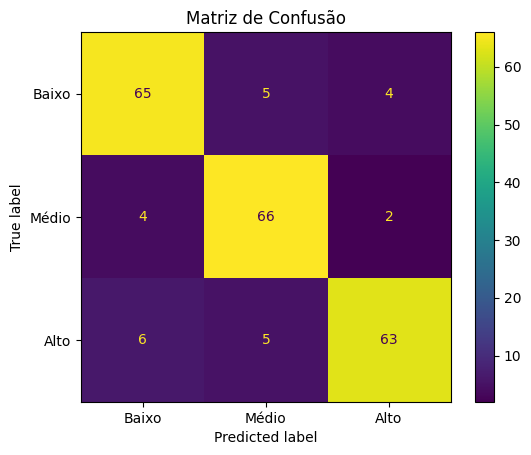

In [ ]:
matriz = confusion_matrix( y_test, ypred, labels= [0, 1, 2]) #cria uma matriz, passando y verdadeiro e y previsto e o labels (0 e 1 e 2)
disp = ConfusionMatrixDisplay(matriz, display_labels=['Baixo', 'Médio', 'Alto']) #aqui é o que serás mostrado no grafico, a matriz da linha anterior, mais os labels
disp.plot() #cria o grafico
plt.title("Matriz de Confusão") #cria o titulo
plt.show() #mostra na tela

A matriz de confusão compara as classes reais com as classes previstas pelo SVM. Neste projeto, ela considera as três classes correspondentes aos níveis de estresse: baixo, médio e alto, desde que essa correspondência seja confirmada na descrição do dataset.
A visualização permite identificar as classificações corretas e os erros entre as classes, ajudando a compreender quais níveis de estresse são mais confundidos pelo modelo.

## 5.5. Arvore de Decisão, Floresta Aleatória e Gradient Boosting

### 5.5.1 Criando os Modelos

In [ ]:
modelos = {
    'Árvore de Decisão': DecisionTreeClassifier(random_state=42),
    'Random Forest': RandomForestClassifier(n_estimators=100, random_state=42),
    'Gradient Boosting': GradientBoostingClassifier(random_state=42)
}
for nome, md in modelos.items():
    md.fit(x_train, y_train)
    print(f'{nome}: treinado')

Árvore de Decisão: treinado
Random Forest: treinado
Gradient Boosting: treinado


Foram criados três classificadores: Árvore de Decisão, Floresta Aleatória (Random Forest) e Gradient Boosting. Cada modelo foi treinado com os mesmos dados de treinamento, permitindo comparar o desempenho dos algoritmos nas mesmas condições.


### 5.5.2 Prevendo

In [ ]:
previsoes = {nome: md.predict(x_test) for nome, md in modelos.items()}
print('Valores reais:', y_test)
for nome, y_pred in previsoes.items():
    print(f'{nome}:', y_pred)

Valores reais: 150     0
582     0
450     2
616     2
1090    0
       ..
1084    2
554     0
369     0
176     2
936     0
Name: stress_level, Length: 220, dtype: int64
Árvore de Decisão: [0 0 2 2 2 0 2 2 1 1 1 0 0 2 0 1 1 2 1 1 0 2 0 1 0 0 1 1 1 0 1 1 1 0 0 2 2
 2 2 2 0 2 2 0 0 2 0 1 2 0 1 1 1 1 0 2 0 0 0 0 1 0 0 2 1 1 2 0 2 2 2 1 2 1
 2 1 0 1 0 1 1 2 2 1 0 2 1 1 1 2 2 0 1 1 0 2 1 2 0 1 2 2 0 1 2 1 2 2 0 0 2
 0 2 1 1 2 1 0 2 2 0 2 2 2 0 1 1 1 0 2 0 0 1 1 2 1 1 1 0 1 2 1 1 0 0 1 0 1
 2 0 2 0 0 1 1 2 0 1 1 0 2 0 0 0 1 2 1 1 0 1 0 1 2 2 2 2 0 0 1 1 0 1 1 2 2
 1 1 1 1 1 2 1 0 0 2 2 2 1 1 2 2 2 2 2 0 2 2 0 1 0 2 0 0 2 2 0 1 0 2 0]
Random Forest: [0 0 2 2 2 0 2 0 1 0 1 0 0 2 2 1 1 2 1 1 0 0 0 1 1 0 1 1 0 1 1 1 1 0 0 2 2
 2 2 2 0 0 2 0 0 2 0 1 2 0 1 1 1 1 0 1 2 0 0 0 1 0 0 2 1 1 2 0 2 2 2 1 2 1
 2 1 0 1 0 1 1 2 2 1 0 2 1 1 1 2 2 0 1 1 0 2 2 2 0 1 2 1 0 1 2 1 2 2 0 0 1
 0 2 1 1 2 1 0 2 2 0 2 2 2 0 1 1 1 0 2 0 0 1 1 2 1 1 1 0 1 2 1 1 2 0 1 0 1
 2 0 2 0 0 1 1 2 0 1 1 0 2 0 0 0 1 0 1 1 0 1 0 1

Após o treinamento, cada classificador foi utilizado para prever as classes do conjunto de teste. As previsões foram armazenadas no dicionário previsoes, facilitando a avaliação e a comparação entre os modelos.

### 5.5.3 Avaliando e Comparando

In [ ]:
label = [0, 1, 2]
resultados = []
for nome, y_pred in previsoes.items():
    acuracia = accuracy_score(y_test, y_pred)
    resultados.append({'Modelo': nome, 'Acurácia': acuracia})
    print(f'\n{nome} — Acurácia: {acuracia:.2%}')
    print(classification_report(y_test, y_pred, labels=label, target_names=[str(classe) for classe in label], zero_division=0))
pd.DataFrame(resultados).sort_values('Acurácia', ascending=False)


Árvore de Decisão — Acurácia: 85.91%
              precision    recall  f1-score   support

           0       0.87      0.81      0.84        74
           1       0.86      0.92      0.89        72
           2       0.85      0.85      0.85        74

    accuracy                           0.86       220
   macro avg       0.86      0.86      0.86       220
weighted avg       0.86      0.86      0.86       220


Random Forest — Acurácia: 89.09%
              precision    recall  f1-score   support

           0       0.90      0.86      0.88        74
           1       0.87      0.93      0.90        72
           2       0.90      0.88      0.89        74

    accuracy                           0.89       220
   macro avg       0.89      0.89      0.89       220
weighted avg       0.89      0.89      0.89       220


Gradient Boosting — Acurácia: 89.55%
              precision    recall  f1-score   support

           0       0.89      0.88      0.88        74
           1       

,Modelo,Acurácia
2,Gradient Boosting,0.895455
1,Random Forest,0.890909
0,Árvore de Decisão,0.859091


Nesta etapa, foi calculada a acurácia de cada classificador e gerado o relatório de classificação com precisão, recall, F1-score e suporte. Os resultados foram organizados em uma tabela ordenada pela acurácia, facilitando a comparação do desempenho dos modelos.

### 5.5.4. Vizualizando

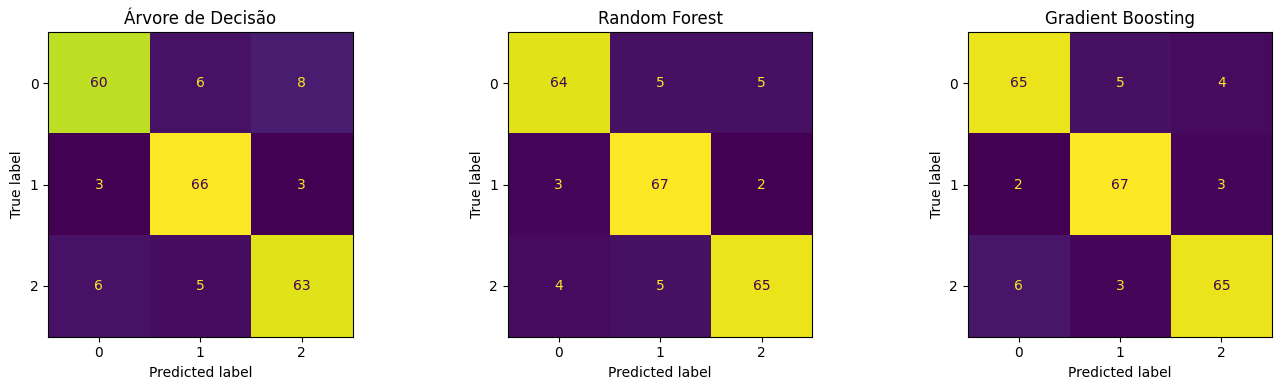

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (nome, y_pred) in zip(axes, previsoes.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=label, display_labels=label, ax=ax, colorbar=False)
    ax.set_title(nome)
plt.tight_layout()
plt.show()

Foram construídas matrizes de confusão para os três classificadores, organizadas lado a lado para facilitar a comparação. Essa visualização permite verificar como cada modelo classificou os registros de teste e quais erros ocorreram em cada classe.

## 5.6 Interpretando

Após realizar os testes, foi possível comparar o desempenho de quatro algoritmos de classificação para prever o nível de estresse dos alunos, dividido em três classes: 0, 1 e 2.

O modelo SVM, utilizando o kernel polinomial (`poly`), alcançou uma acurácia de 88% no conjunto de teste. Na validação cruzada, o modelo apresentou uma acurácia média de 86%, indicando resultados relativamente próximos aos obtidos no teste.

Na comparação com os demais classificadores, a Árvore de Decisão apresentou uma acurácia de 85%, enquanto a Floresta Aleatória e o Gradient Boosting alcançaram 89%. Portanto, considerando os resultados informados, a Floresta Aleatória e o Gradient Boosting obtiveram as maiores acurácias no conjunto de teste, seguidos pelo SVM e pela Árvore de Decisão.

Esses resultados mostram que os modelos de Floresta Aleatória e Gradient Boosting tiveram o melhor desempenho geral em relação à acurácia neste experimento. Entretanto, como a diferença entre os resultados é pequena, é importante analisar também as métricas de precisão, recall e F1-score para cada classe, além das matrizes de confusão, a fim de verificar se os modelos conseguem distinguir adequadamente os três níveis de estresse.

Conclui-se que os algoritmos avaliados apresentaram resultados satisfatórios para a classificação do nível de estresse dos alunos neste conjunto de dados. A Floresta Aleatória e o Gradient Boosting se destacaram pela maior acurácia no teste, enquanto a proximidade entre a acurácia de teste e a média da validação cruzada do SVM sugere um desempenho relativamente consistente nessas duas avaliações. Ainda assim, são necessárias análises complementares para avaliar a capacidade de generalização dos modelos e identificar possíveis diferenças no desempenho entre as classes.

#6. Eleição Norte-Americana de 1936

## 6.1.­ Lendo os dados do excel

In [ ]:
df_1936 = pd.read_excel('/content/LitDigestFull.xlsx', sheet_name='1936') #usei o read_excel do pandas pra poder ler o arquivo, e precisei colocar sheet_name pois dentro do arquivo tinha de vários anos, e como estamos focando em 1936 foi necessário

In [ ]:
df_1932 = pd.read_excel('/content/LitDigestFull.xlsx', sheet_name='1932') #aqui fez igual no de cima para os dados da pesquisa de 1932.

## 6.2.­ Verificando os dados existentes

### 6.2.1. Head

In [ ]:
df_1936.head() #Mostra as 5 primeiras linhas

,Unnamed: 0,Unnamed: 1,Landon (R),How did they vote in 1932?,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9,...,%.3,Electoral votes.4,Other,%.4,Electoral votes.5,Margin,%.5,Total votes,State,Unnamed: 55
0,State,Electoral Vote,Landon,Rep.,Dem.,Soc.,Others,Did Not Vote,Vote Not Indicated,NaN,...,0.09,-,1397,0.51,-,202838.0,73.56,275244.0,AL,https://en.wikipedia.org/wiki/1936_United_Stat...
1,Alabama,11,3060,1218,1298,3,3,412,126,NaN,...,0.26,-,384,0.31,-,53289.0,42.92,124163.0,AZ,NaN
2,Arizona,3,2337,1431,647,18,0,129,112,NaN,...,0.25,-,169,0.09,-,114726.0,63.94,179423.0,AR,NaN
3,Arkansas,9,2724,1338,953,7,9,274,143,NaN,...,0.43,-,24284,0.92,-,930405.0,35.26,2638882.0,CA,NaN
4,California,22,89516,65360,16200,315,53,3519,4069,NaN,...,0.33,-,841,0.17,-,113754.0,23.28,488684.0,CO,NaN


In [ ]:
df_1932.head()

,Unnamed: 0,Unnamed: 1,HOOVER,How the same Voters voted in 1928,Unnamed: 4,Unnamed: 5,Unnamed: 6,Unnamed: 7,Unnamed: 8,ROOSEVELT,...,Thomas (Soc.),%.2,Electoral votes.3,Other,%.3,Electoral votes.4,Margin,%.4,Total votes,Unnamed: 44
0,NaN,Electoral Votes,1932 Total Vote,Rep.,Dem.,Other,Did Not Vote,NaN,NaN,1932 Total Vote,...,2030.0,0.83,–,739.0,0.30,–,173235,70.61,245354.0,https://en.wikipedia.org/wiki/1932_United_Stat...
1,ALABAMA,11,4272,3150,480,1,641,NaN,NaN,20161,...,2618.0,2.21,–,265.0,0.22,–,43160,36.5,118251.0,NaN
2,ARIZONA,3,2574,2022,218,1,333,NaN,NaN,4910,...,1269.0,0.58,–,1224.0,0.55,–,161135,73.06,220562.0,NaN
3,ARKANSAS,9,3712,2997,250,1,464,NaN,NaN,16225,...,63299.0,2.79,–,32608.0,1.44,–,476255,21,2267966.0,NaN
4,CALIFORNIA,22,81834,67017,3847,99,10871,NaN,NaN,148832,...,13591.0,2.97,–,3611.0,0.79,–,61260,13.38,457696.0,NaN


### 6.2.2. Shape

In [ ]:
df_1936.shape #mostra a forma do gráfico entre linhas e colunas

(51, 56)

In [ ]:
df_1932.shape

(52, 45)

### 6.2.3. Info

In [ ]:
df_1936.info() #as informações

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 51 entries, 0 to 50
Data columns (total 56 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   Unnamed: 0                    51 non-null     object 
 1   Unnamed: 1                    51 non-null     object 
 2   Landon  (R)                   51 non-null     object 
 3   How did they vote in 1932?    51 non-null     object 
 4   Unnamed: 4                    51 non-null     object 
 5   Unnamed: 5                    51 non-null     object 
 6   Unnamed: 6                    51 non-null     object 
 7   Unnamed: 7                    51 non-null     object 
 8   Unnamed: 8                    51 non-null     object 
 9   Unnamed: 9                    0 non-null      float64
 10  Roosevelt  (D)                51 non-null     object 
 11  How did they vote in 1932?.1  51 non-null     object 
 12  Unnamed: 12                   51 non-null     object 
 13  Unnamed

In [ ]:
df_1932.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52 entries, 0 to 51
Data columns (total 45 columns):
 #   Column                               Non-Null Count  Dtype  
---  ------                               --------------  -----  
 0   Unnamed: 0                           51 non-null     object 
 1   Unnamed: 1                           51 non-null     object 
 2   HOOVER                               52 non-null     object 
 3   How the same Voters voted in 1928    52 non-null     object 
 4   Unnamed: 4                           52 non-null     object 
 5   Unnamed: 5                           52 non-null     object 
 6   Unnamed: 6                           52 non-null     object 
 7   Unnamed: 7                           0 non-null      float64
 8   Unnamed: 8                           0 non-null      float64
 9   ROOSEVELT                            52 non-null     object 
 10  How the same Voters voted in 1928.1  52 non-null     object 
 11  Unnamed: 11                       

### 6.2.4. Describe

In [ ]:
df_1936.describe() #a descrição detalhada, contendo count, mean, std, min, max, etc

,Unnamed: 9,Unnamed: 17,Unnamed: 25,Unnamed: 33,Electoral votes,Roosevelt,%,Landon,%.1,Margin,%.5,Total votes
count,0.0,0.0,0.0,0.0,49.000000,4.900000e+01,49.000000,4.900000e+01,49.000000,4.900000e+01,49.000000,4.900000e+01
mean,NaN,NaN,NaN,NaN,21.673469,1.132766e+06,64.652653,6.809107e+05,32.978980,4.518688e+05,31.673673,1.863179e+06
std,NaN,NaN,NaN,NaN,74.808474,3.940307e+06,12.574029,2.378896e+06,11.829567,1.567596e+06,24.273271,6.490007e+06
min,NaN,NaN,NaN,NaN,3.000000,3.192500e+04,41.520000,1.646000e+03,1.430000,-4.249000e+04,-13.970000,4.384800e+04
25%,NaN,NaN,NaN,NaN,4.000000,1.573180e+05,56.880000,6.455500e+04,27.590000,8.569100e+04,16.400000,2.305120e+05
50%,NaN,NaN,NaN,NaN,9.000000,3.280830e+05,60.800000,1.688230e+05,36.540000,1.581770e+05,25.310000,4.886840e+05
75%,NaN,NaN,NaN,NaN,13.000000,7.344850e+05,69.340000,3.977270e+05,40.180000,3.170610e+05,40.840000,1.142733e+06
max,NaN,NaN,NaN,NaN,531.000000,2.775265e+07,98.570000,1.668186e+07,56.390000,1.107079e+07,97.150000,4.564770e+07


In [ ]:
df_1932.describe()

,Unnamed: 7,Unnamed: 8,Unnamed: 14,Unnamed: 15,Unnamed: 23,Unnamed: 25,Unnamed: 26,Electoral votes,Roosevelt,%,Hoover,%.1,Thomas (Soc.),%.2,Other,%.3,Total votes
count,0.0,0.0,0.0,0.0,0.0,0.0,0.0,49.000000,4.900000e+01,49.000000,4.900000e+01,49.000000,49.000000,49.000000,49.000000,49.000000,4.900000e+01
mean,NaN,NaN,NaN,NaN,NaN,NaN,NaN,21.673469,9.314807e+05,62.660000,6.433165e+05,35.076735,36117.755102,1.627347,11611.510204,0.636735,1.622526e+06
std,NaN,NaN,NaN,NaN,NaN,NaN,NaN,74.808474,3.231771e+06,13.945857,2.245564e+06,13.245745,127692.119176,1.227624,40910.494044,0.919201,5.642061e+06
min,NaN,NaN,NaN,NaN,NaN,NaN,NaN,3.000000,2.875600e+04,41.080000,1.978000e+03,1.890000,0.000000,0.000000,0.000000,0.000000,4.143000e+04
25%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,4.000000,1.401680e+05,54.470000,7.141700e+04,30.530000,1551.000000,0.540000,265.000000,0.140000,2.205620e+05
50%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,9.000000,2.594730e+05,58.660000,1.666310e+05,36.880000,4450.000000,1.360000,2235.000000,0.440000,4.576960e+05
75%,NaN,NaN,NaN,NaN,NaN,NaN,NaN,13.000000,7.074100e+05,68.460000,3.947160e+05,43.310000,20480.000000,2.460000,5203.000000,0.750000,1.036687e+06
max,NaN,NaN,NaN,NaN,NaN,NaN,NaN,531.000000,2.282128e+07,98.030000,1.576125e+07,57.660000,884885.000000,4.790000,284482.000000,5.830000,3.975190e+07


### 6.2.5. Verificando nulos

In [ ]:
df_1936.isnull().sum() #aqui fiz a primeira verificação de nulos para entender o que precisaria ser limpo

,0
Unnamed: 0,0
Unnamed: 1,0
Landon (R),0
How did they vote in 1932?,0
Unnamed: 4,0
Unnamed: 5,0
Unnamed: 6,0
Unnamed: 7,0
Unnamed: 8,0
Unnamed: 9,51


In [ ]:
df_1932.isnull().sum()

,0
Unnamed: 0,1
Unnamed: 1,1
HOOVER,0
How the same Voters voted in 1928,0
Unnamed: 4,0
Unnamed: 5,0
Unnamed: 6,0
Unnamed: 7,52
Unnamed: 8,52
ROOSEVELT,0


Identificamos a presença de colunas totalmente nulas, e a presença de linhas dentro de colunas que precisam ser apagadas, por isso separei a divisão delas a seguir

## 6.3.­ Remoção de colunas desnecessárias

In [ ]:
df_1936 = df_1936.dropna(how='all', axis=1) #essa linha faz com que todas as colunas sem informações sejam apagadas
df_1936 = df_1936.drop(columns=['Unnamed: 55']) #precisei executar essa linha de código para excluir especificamente a unnamed: 55 que não foi apagada antes

In [ ]:
df_1936.isnull().sum()

,0
Unnamed: 0,0
Unnamed: 1,0
Landon (R),0
How did they vote in 1932?,0
Unnamed: 4,0
Unnamed: 5,0
Unnamed: 6,0
Unnamed: 7,0
Unnamed: 8,0
Roosevelt (D),0


In [ ]:
df_1932 = df_1932.dropna(how='all', axis=1)
df_1932 = df_1932.drop(columns=['Unnamed: 44'])

In [ ]:
df_1932.isnull().sum()

,0
Unnamed: 0,1
Unnamed: 1,1
HOOVER,0
How the same Voters voted in 1928,0
Unnamed: 4,0
Unnamed: 5,0
Unnamed: 6,0
ROOSEVELT,0
How the same Voters voted in 1928.1,0
Unnamed: 11,0


## 6.4.­ Remoção de linhas desnecessárias

In [ ]:
df_1936 = df_1936.dropna(how='all', axis=0) #aqui eu usei esse comando para limpar as linhas que não tinham nada

In [ ]:
df_1932 = df_1932.dropna(how='all', axis=0)

In [ ]:
df_1936.isnull().sum()

,0
Unnamed: 0,0
Unnamed: 1,0
Landon (R),0
How did they vote in 1932?,0
Unnamed: 4,0
Unnamed: 5,0
Unnamed: 6,0
Unnamed: 7,0
Unnamed: 8,0
Roosevelt (D),0


In [ ]:
df_1932.isnull().sum()

,0
Unnamed: 0,1
Unnamed: 1,1
HOOVER,0
How the same Voters voted in 1928,0
Unnamed: 4,0
Unnamed: 5,0
Unnamed: 6,0
ROOSEVELT,0
How the same Voters voted in 1928.1,0
Unnamed: 11,0


## 6.5.­ Remoção de linhas sem nome

algumas linhas ficaram sobrando por conta da formatação, e por conta disso, pesquisei como solucionar

In [ ]:
df_1936 = df_1936.dropna(subset=['State - 1936']) #aqui usei esse comando para o pandas olhas especificamente para a coluna do nome do estado, e caso estiver em branco as linhas, ele apaga, se não ele mantem
df_1936 = df_1936.loc[:, ~df_1936.columns.str.contains('^Unnamed')] #aqui sobrou algumas então usei esse comando para apagar especificamente as colunas que contenham o nome Unnamed

In [ ]:
df_1936.isnull().sum()

,0
Landon (R),0
How did they vote in 1932?,0
Roosevelt (D),0
How did they vote in 1932?.1,0
Lemke (Union),0
How did they vote in 1932?.2,0
MINOR CANDIDATES,0
Grand Total Votes,0
State - 1936,0
Electoral votes,0


In [ ]:
df_1932 = df_1932.dropna(subset=['State - 1932'])
df_1932 = df_1932.loc[:, ~df_1932.columns.str.contains('^Unnamed')]
df_1932 = df_1932.dropna(subset=["Electoral votes.4"])

In [ ]:
df_1932.isnull().sum()

,0
HOOVER,0
How the same Voters voted in 1928,0
ROOSEVELT,0
How the same Voters voted in 1928.1,0
VOTES FOR MINOR CANDIDATES,0
GRAND TOTAL VOTES,0
State - 1932,0
Electoral votes,0
Roosevelt,0
%,0


## 6.6. Remover linhas Totais de cada um dos dataframe

In [ ]:
df_1932_reg = df_1932[
    df_1932["State - 1932"] != "Total"
].copy() #copia tudo que for diferente da coluna Total para um novo dataframe _reg

df_1936_reg = df_1936[
    df_1936["State - 1936"] != "Total"
].copy()

Criando duas copias dos dataframes sem as colunas Total, já que ela será inutil na regressão

In [ ]:
df_1936_reg["Landon  (R)"] = pd.to_numeric(
    df_1936_reg["Landon  (R)"], errors="coerce"
) #transforma os dados de votos de cada estado de cada candidato em numero, para facilitar calculos futuros.

df_1936_reg["Roosevelt  (D)"] = pd.to_numeric(
    df_1936_reg["Roosevelt  (D)"], errors="coerce"
)

df_1936_reg["Lemke (Union)"] = pd.to_numeric(
    df_1936_reg["Lemke (Union)"], errors="coerce"
)

Transformando os dados em numericos, para calculos futuros.

In [ ]:
df_1936_reg = df_1936_reg.dropna(
    subset=["Landon  (R)", "Roosevelt  (D)", "Lemke (Union)"]
).copy() #dropa todas as linhas que possuam dados nulos.

Dropando mais colunas que podem estar vazias.

### 6.6.1 Adicionar porcentagens a pesquisa de 1936

In [ ]:
total_pesquisa_1936 = (
    df_1936_reg["Landon  (R)"] +
    df_1936_reg["Roosevelt  (D)"] +
    df_1936_reg["Lemke (Union)"]
)

df_1936_reg["Roosevelt_pesquisa"] = (
    df_1936_reg["Roosevelt  (D)"] / total_pesquisa_1936 * 100
)
df_1936_reg["Landon_pesquisa"] = (
    df_1936_reg["Landon  (R)"] / total_pesquisa_1936 * 100
)
df_1936_reg["Lemke_pesquisa"] = (
    df_1936_reg["Lemke (Union)"] / total_pesquisa_1936 * 100
) #soma o total de pessoas ouvidas na pesquisa, em seguida calcula a porcentagem de cada candidato.

Para facilitar o trabalho futuramente, criei porcentagens na pesquisa de intenção de voto em cada um dos estados/canditados

### 6.6.2 Criando uma margem de erro do resultado real de 36, para a pesquisa da Literary Digest

In [ ]:
df_1936_reg["erro_Roosevelt"] = (
    df_1936_reg["Roosevelt_pesquisa"] -
    df_1936_reg["%"]
) #cria uma margem de erro no roosevelt, comparando o resultado da pesquisa dele com o reultado final da eleição dele.

Aqui cria uma coluna margem de erro, subtraindo o valor da pesquisa de intencao de voto, pela quantidade de votos recebidos por Roosevelt, assim vamos ver em cada estado a margem de erro.

In [ ]:
print(df_1936_reg[["State - 1936","Landon_pesquisa","Roosevelt_pesquisa","Lemke_pesquisa"]].head())

  State - 1936  Landon_pesquisa  Roosevelt_pesquisa  Lemke_pesquisa
1      Arizona        23.164269           76.320969        0.514762
2     Arkansas        52.921196           44.723732        2.355072
3   California        26.017192           72.664756        1.318052
4     Colorado        52.123584           44.978397        2.898019
5  Connecticut        60.064776           37.754679        2.180545


Printando 5 primeiras porcentagens para ver se tudo está correto.

### 6.6.4 Fundindo os dataframes

In [ ]:
df_reg = df_1936_reg.merge(
    df_1932_reg,
    left_on="State - 1936",
    right_on="State - 1932",
    how="inner"
) #utilizando o comando merge, fundiu os dois dataframes pelos estados, onde 36 fica a esquerda(x) e 32 a direita(y).

Para melhor trabalho futuro, usou .erge para juntar as tabelas de 1936, pesquisa e 1932(resultado)

In [ ]:
print(df_reg[["State - 1936","State - 1932"]].head())

  State - 1936 State - 1932
0      Arizona      Arizona
1     Arkansas     Arkansas
2   California   California
3     Colorado     Colorado
4  Connecticut  Connecticut


Aqui foi printado para ver se a junção foi correta, como pode ver estão agora na mesma tabela.

### 6.6.5 Analises mais profundas em 1932

In [ ]:
total_pesquisa_1932 = (df_reg["HOOVER"] +df_reg["ROOSEVELT"])
df_reg["Roosevelt_pesquisa_1932"] = (df_reg["ROOSEVELT"] / total_pesquisa_1932 * 100) #parecido com o que foi feito anteriormente, pegamos a porcentagem de roosevelt em 1932

In [ ]:
df_reg["erro_Roosevelt_1932"] = (df_reg["Roosevelt_pesquisa_1932"] -df_reg["%_y"]) #calculo da margem de erro de 1932, com o valor da pesquisa - o valor oficial

In [ ]:
print(df_reg[["State - 1932","Roosevelt_pesquisa_1932","%_y","erro_Roosevelt_1932" ]].head()) #printando os 5 primerios com o estado, resultado da pesquisa e o oficial e a margem de erro.

  State - 1932 Roosevelt_pesquisa_1932    %_y erro_Roosevelt_1932
0      Arizona                82.51545  67.03            15.48545
1     Arkansas               65.606627  85.96          -20.353373
2   California               81.381351  58.39           22.991351
3     Colorado                64.52273  54.81             9.71273
4  Connecticut               54.483126  47.40            7.083126


In [ ]:
df_reg["Roosevelt_corrigido_1936"] = (df_reg["Roosevelt_pesquisa"] - df_reg["erro_Roosevelt_1932"]) #aqui uma correção de quanto deveria ser o valor de roosevelt em 36 com o valor da pesquisa de 36 - a margem de erro de 32.

In [ ]:
df_reg["erro_corrigido_1936"] = (df_reg["Roosevelt_corrigido_1936"] -df_reg["%_x"]) #corrigindo a margem de erro de 1936 com o valor obtido anteriormente(o que deveria ser) - o valor obtido oficialemnte por roosevelt

In [ ]:
df_reg["erro_original_abs"] = df_reg["erro_Roosevelt"].abs() #aqui transformamos a margem de erro de 1936 original em valor absoluto, ou seja, sem valores negativos. Virando pontos percentuais. -20 ou 20 vira 20 pp.

In [ ]:
df_reg["erro_corrigido_abs"] = df_reg["erro_corrigido_1936"].abs() #mesma coisa com a margem de erro corrigida

In [ ]:
print("Erro médio original:",df_reg["erro_original_abs"].mean())
print("Erro médio corrigido:",df_reg["erro_corrigido_abs"].mean()) # aqui tiramos a media dos dois erros absolutos, resultando em valores bem parecidos.

Erro médio original: 23.28304150341117
Erro médio corrigido: 24.131892892036763


Nesse ponto 7.5 foi basicamente trabalhar e estudar melhor os dados da eleição de 1932 para poder usá-los futuramente na regressão linear, iniciamos calculando as porcentagens da pesquisa de 1932, depois sua margem de erro. Com essa margem de erro, tentamos corrigir os valores de votos para Roosevelt em 36 a margem de erro de 1936, para valores mais aceitaveis. Por ultimo, foi transformado o erro original, aquele calculado em 7.2 e a margem de erro mais aceitavel calculado nesse em numeros absolutos, para melhor calculo e finalizando, foi calculada a media das margens de erros.

## 6.7.­ Graficos para visualização inicial

### 6.7.1. Gráfico 1: Porcentagem de Votos (Previsão vs. Realidade)

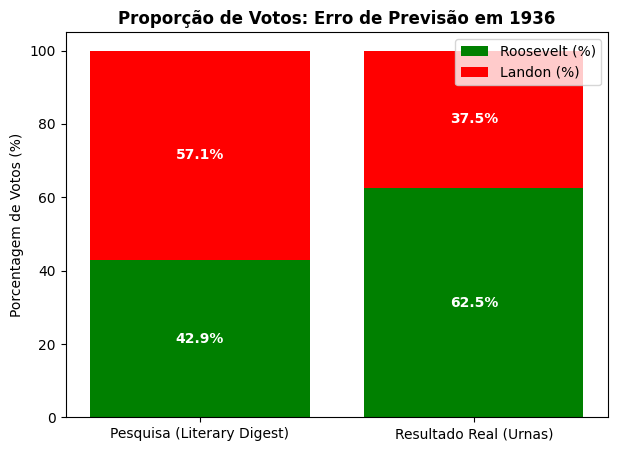

In [ ]:
categorias = ['Pesquisa (Literary Digest)', 'Resultado Real (Urnas)'] #as categorias
roosevelt_pcts = [42.9, 62.5] #Percentual tirado da coluna de resultados presente no excel, fiz uma regra de 3 com os resultados para descobrir as porcentagens
landon_pcts = [57.1, 37.5] #mesma coisa aqui

plt.figure(figsize=(7, 5)) #defini o tamanho do grafico
bar1 = plt.bar(categorias, roosevelt_pcts, label='Roosevelt (%)', color='green')
bar2 = plt.bar(categorias, landon_pcts, bottom=roosevelt_pcts, label='Landon (%)', color='red')

plt.ylabel('Porcentagem de Votos (%)') #criei o titulo ali do lado esquerdo presente no Y
plt.title('Proporção de Votos: Erro de Previsão em 1936', fontweight='bold') #O titulo
plt.legend(loc='upper right') #e movi a legenda pro lado direito pois estava muito poluido do outro lado

#Texto que coloquei na primeira coluna (Pesquisa)
plt.text(0, 42.9 / 2, '42.9%', ha='center', va='center', color='white', fontweight='bold') #Roosevelt (barra de baixo), aqui eu coloquei a primeira coluna, e o alinhamento horizontal e vertical pra ficar certinho, a cor do texto e a fonte negrito
plt.text(0, 42.9 + (57.1 / 2), '57.1%', ha='center', va='center', color='white', fontweight='bold') #Landon (barra de cima: 42.9 + metade de 57.1)

#texto na segunda coluna (Resultado Real)
plt.text(1, 62.5 / 2, '62.5%', ha='center', va='center', color='white', fontweight='bold')#Roosevelt (barra de baixo), mesma coisa aqui
plt.text(1, 62.5 + (37.5 / 2), '37.5%', ha='center', va='center', color='white', fontweight='bold') #Landon (barra de cima: 62.5 + metade de 37.5)

plt.show() #Aqui eu mostrei

Esse gráfico mostra claramente o erro da previsão de 1936, notamos que na barra da esquerda, onde se trata da pesquisa, Landon estava na frente tratando dos votos declarados, e na barra da direita, onde se trata dos resultados reais, notamos que nas urnas o Roosevelt ganhou com uma diferença consideravel

### 6.7.2. Gráfico 2: Comparativo do Total de Votos: Pesquisa vs. Urnas

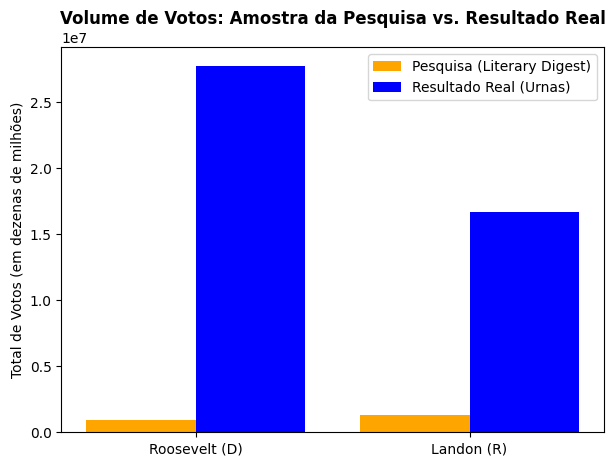

In [ ]:
candidatos = ['Roosevelt (D)', 'Landon (R)'] #defini os candidatos presentes
votos_pesquisa = [964819, 1283985]#peguei os votos declarados na pesquisa
votos_reais = [27752889, 16682763]#e os votos oficiais das urnas

plt.figure(figsize=(7, 5)) #defini o tamanho de novo

x = [0, 1] #fiz um grafico de barras, e descobri que fazendo desse modo, as barras ficam lado a lado
largura = 0.40 #Largura de cada barra

plt.bar([pos - largura/2 for pos in x], votos_pesquisa, width=largura, label='Pesquisa (Literary Digest)', color='orange') #Barras da Pesquisa(deslocadas um pouco para a esquerda)

plt.bar([pos + largura/2 for pos in x], votos_reais, width=largura, label='Resultado Real (Urnas)', color='blue') #barras do Resultado Real (deslocadas um pouco para a direita)

plt.ylabel('Total de Votos (em dezenas de milhões)') #aqui os eixos colocados
plt.title('Volume de Votos: Amostra da Pesquisa vs. Resultado Real', fontweight='bold') #o titulo
plt.xticks(x, candidatos) #coloca o nome dos candidatos no eixo X
plt.legend(loc='upper right') #legenda no canto superior direito

plt.show() #mostra

Nesse gráfico notamos a diferença enorme entre o volume de votos, as pesquisas possuíam um número muito abaixo do resultado real das urnas
concluimos com isso que mesmo a pesquisa tendo abrangido um numero grande de entrevistados, a dimensao da previsao não evitou um grande erro no resultado

## 6.8. Diagnóstico de Vieses

### 6.8.1 Viés de Amostragem

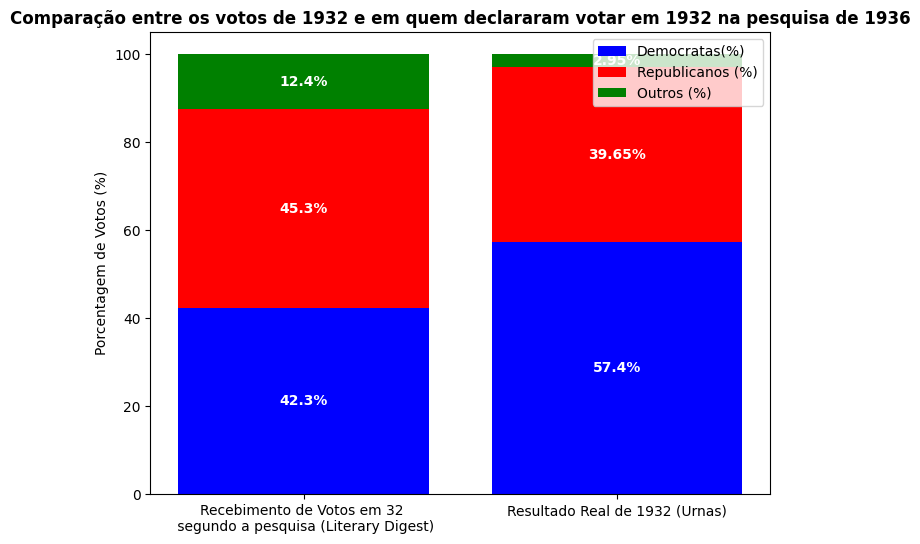

In [ ]:
categorias = [f'Recebimento de Votos em 32 \n segundo a pesquisa (Literary Digest)', 'Resultado Real de 1932 (Urnas)'] #as categorias
dem = [42.3, 57.4] #porcentagem declarada de votos de 32 na pesquisa de 36 e outra recebida dos democratas em 1932
rep = [45.3, 39.65] #mesma coisa aqui para os republicanos
outros= [12.4, 2.95] #mesma coisa aqui para nenhum dos dois partidos

plt.figure(figsize=(8, 6)) #defini o tamanho do grafico
bar1 = plt.bar(categorias, dem, label='Democratas(%)', color='blue')
bar2 = plt.bar(categorias, rep, bottom=dem, label='Republicanos (%)', color='red')
bar3 = plt.bar(categorias, outros, bottom=[dem[i]+rep[i] for i in range(len(categorias))], label='Outros (%)', color='green')

plt.ylabel('Porcentagem de Votos (%)') #criei o titulo ali do lado esquerdo presente no Y
plt.title('Comparação entre os votos de 1932 e em quem declararam votar em 1932 na pesquisa de 1936', fontweight='bold') #O titulo
plt.legend(loc='upper right') #e movi a legenda pro lado direito pois estava muito poluido do outro lado

#Texto que coloquei na primeira coluna (votos em 1932)
plt.text(1, 57.4 / 2, '57.4%', ha='center', va='center', color='white', fontweight='bold') #Democratas (barra de baixo), aqui eu coloquei a primeira coluna, e o alinhamento horizontal e vertical pra ficar certinho, a cor do texto e a fonte negrito
plt.text(1, 57.4 + (39.65 / 2), '39.65%', ha='center', va='center', color='white', fontweight='bold') #Republicanos
plt.text(1, 57.4 + ((39.65)+2.95/2), '2.95%', ha='center', va='center', color='white', fontweight='bold') #Outros

#texto na segunda coluna (pesquisa de 36 sobre em quem votou em 32)
plt.text(0, 42.3 / 2, '42.3%', ha='center', va='center', color='white', fontweight='bold')#Democratas (barra de baixo), mesma coisa aqui
plt.text(0, 42.3 + (45.3 / 2), '45.3%', ha='center', va='center', color='white', fontweight='bold') #Republicanos
plt.text(0, 42.3 + ((45.3)+12.4/2), '12.4%', ha='center', va='center', color='white', fontweight='bold') #Outros

plt.show() #Aqui eu mostrei

Após a análise do gráfico, observa-se uma diferença significativa entre a composição política dos eleitores em 1932 e a composição dos respondentes da pesquisa realizada pela Literary Digest em 1936, considerando como esses respondentes declararam ter votado no ano anterior. Nos resultados eleitorais de 1932, 57,4% dos votos foram destinados aos democratas, enquanto 39,65% foram destinados aos republicanos e aproximadamente 2% a outros candidatos. Entre os respondentes da pesquisa de 1936, entretanto, 42% declararam ter votado nos democratas e 45% nos republicanos, enquanto a participação dos demais grupos aumentou. Dessa forma, observa-se uma redução de aproximadamente 15 pontos percentuais na representação democrata e um aumento de aproximadamente 5 pontos percentuais na representação republicana entre as duas distribuições. Essa diferença indica que a composição política dos respondentes da pesquisa não correspondia à distribuição observada na eleição de 1932, fornecendo evidências de um possível problema de representatividade da amostra. Esse resultado ajuda a explicar por que uma pesquisa com um número tão elevado de respostas poderia ainda assim produzir uma previsão bastante distante do resultado eleitoral de 1936.

### 6.8.2 Viés de Não Resposta

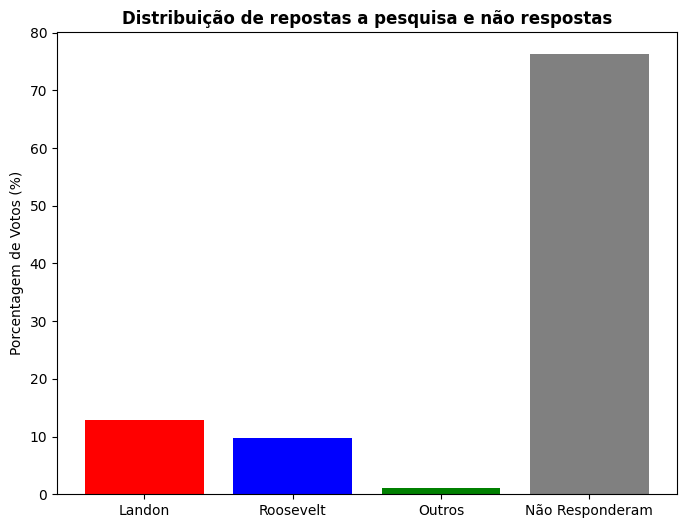

In [ ]:
categorias = ["Landon", "Roosevelt", "Outros", "Não Responderam"] #as categorias
valores = [12.94, 9.73, 1.10, 76.23]
plt.figure(figsize=(8, 6)) #defini o tamanho do grafico
plt.bar(categorias, valores, color=["red", "blue", "green", "gray"])

plt.ylabel('Porcentagem de Votos (%)') # Foi criado o titulo do lado esquerdo presente no Y
plt.title('Distribuição de repostas a pesquisa e não respostas', fontweight='bold') # O titulo

plt.show() # Aqui foi mostrado

Após a criação do gráfico, é possível perceber uma grande discrepância entre os valores declarados para cada candidato e a quantidade de pessoas que não responderam à pesquisa, que chega a aproximadamente 76%. Esse alto percentual de não respostas representa um possível problema de viés de não resposta, pois a pesquisa considera apenas as pessoas que efetivamente responderam ao questionário. Não é possível saber qual era a preferência política dos indivíduos que não responderam e, portanto, não podemos afirmar que a distribuição observada entre os respondentes representava a população geral. Por exemplo, caso os não respondentes apresentassem uma composição política diferente da observada entre os respondentes, o resultado estimado pela pesquisa poderia mudar significativamente.

## 6.9. Iniciando a Regressão

### 6.9.1 definição de X e Y

In [ ]:
x = df_reg[["erro_Roosevelt_1932"]]
y = df_reg[["erro_Roosevelt"]]

Primeiro passamos as caracteristicas da pesquisa para X, ou seja a margem de erro de 1932(um valor mais aceitavel, pois naquele ano a pesquisa foi bem sucedida). e passamos a variavel alvo para y, a margem de erro de 1936.

### 6.9.2 Separação de treino e teste

In [ ]:
x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.2,
    random_state=42,
)

Fizemos aqui a separação dos dados de teste e treino, em 80% treino e 20% teste.

In [ ]:
print("X_train:", x_train.shape)
print("X_test :", x_test.shape)
print("\nDistribuição em y_train:")
print(y_train.value_counts())
print("\nDistribuição em y_test:")
print(y_test.value_counts())

X_train: (37, 1)
X_test : (10, 1)

Distribuição em y_train:
erro_Roosevelt
-60.635833        1
-45.333818        1
-37.076268        1
-36.095640        1
-35.148190        1
-34.755026        1
-34.479273        1
-31.847628        1
-29.719717        1
-29.351903        1
-29.255415        1
-27.069250        1
-24.885467        1
-23.934360        1
-22.702773        1
-21.320545        1
-19.599435        1
-18.768378        1
-17.456473        1
-17.378501        1
-17.188848        1
-15.391603        1
-14.047874        1
-14.037386        1
-13.720464        1
-9.986667         1
-9.104415         1
-0.857542         1
 0.886592         1
 5.714756         1
 6.470969         1
 12.715387        1
 13.041509        1
 13.469163        1
 22.057118        1
 26.458477        1
 30.846221        1
Name: count, dtype: int64

Distribuição em y_test:
erro_Roosevelt
-74.809444        1
-37.316876        1
-34.734172        1
-31.557180        1
-29.947773        1
-20.566515        1

Aqui conferimos se os valores realmente foram divididos da forma solicitada e se não houve nenhum erro.

### 6.9.3 Criação do modelo e treino dele

In [ ]:
modelo = LinearRegression()
modelo.fit(x_train, y_train)

LinearRegression()

passamos para a maquina que o modelo desejado é Regressão Linear(LinearRegression()) e depois disso treinamos o modelo com .fit e passando os dados de treino x e y

### 6.9.4 Coeficiente e Intercepto

In [ ]:
print("Coeficiente:", modelo.coef_[0])
print("Intercepto:", modelo.intercept_)

Coeficiente: [0.30964258]
Intercepto: [-16.01188926]


nesses dois prints, primeiro calculamos o coefieciente com nosso modelo de regressão. Tentamos descobrir quantos pontos de erro se aumenta na margem de 36 se aumentar 1 ponto em 32. nesse caso foi 0.3. Já o intercepto é o valor previsto para margem de erro de 36 se a margem de erro de 32 for 0. Nesse caso é -16.

### 6.9.5 Teste do modelo

In [ ]:
df_reg["erro_1936_previsto"] = modelo.predict(x)

Após fazer esses calculos, fazemos o predict com o modelo, salvando eles no dataframe como erro previsto de 1936.

In [ ]:
df_reg[["State - 1936","erro_Roosevelt_1932","erro_Roosevelt","erro_1936_previsto"]].head(10)

,State - 1936,erro_Roosevelt_1932,erro_Roosevelt,erro_1936_previsto
0,Arizona,15.48545,6.470969,-11.216934
1,Arkansas,-20.353373,-37.076268,-22.314160
2,California,22.991351,5.714756,-8.892788
3,Colorado,9.71273,-15.391603,-13.004415
4,Connecticut,7.083126,-17.565321,-13.818652
5,Delaware,-9.164598,-23.934360,-18.849639
6,Florida,-23.036998,-35.148190,-23.145125
7,Georgia,-35.354168,-29.255415,-26.959045
8,Idaho,13.073317,13.469163,-11.963834
9,Illinois,31.618277,-17.456473,-6.221525


Aqui printamos a tabela com a nova coluna erro previsto.

In [ ]:
df_reg["Roosevelt_corrigido_modelo"] = (df_reg["Roosevelt_pesquisa"] -df_reg["erro_1936_previsto"])

Agora vamos corrigir de acordo com o modelo, subtraindo do valor obtido na pesquisa a margem de erro definida pelo modelo.

In [ ]:
df_reg[["State - 1936","Roosevelt_pesquisa","erro_1936_previsto","Roosevelt_corrigido_modelo","%_x"
]].head(10)

,State - 1936,Roosevelt_pesquisa,erro_1936_previsto,Roosevelt_corrigido_modelo,%_x
0,Arizona,76.320969,-11.216934,87.537903,69.85
1,Arkansas,44.723732,-22.314160,67.037892,81.80
2,California,72.664756,-8.892788,81.557544,66.95
3,Colorado,44.978397,-13.004415,57.982812,60.37
4,Connecticut,37.754679,-13.818652,51.573331,55.32
5,Delaware,30.685640,-18.849639,49.535279,54.62
6,Florida,40.951810,-23.145125,64.096934,76.10
7,Georgia,57.844585,-26.959045,84.803629,87.10
8,Idaho,76.429163,-11.963834,88.392997,62.96
9,Illinois,40.243527,-6.221525,46.465051,57.70


Agora, é mostrado na tabela novamente o valor da pesquisa, e o que deveria ser de acordo com o modelo e na ultima coluna o resultado oficial, já é possivel ver que em muitos estado o valor se aproximou do que foi oficialmente.

In [ ]:
df_reg["erro_modelo_abs"] = (df_reg["Roosevelt_corrigido_modelo"] - df_reg["%_x"]).abs()

fazendo o erro absoluto do modelo

In [ ]:
df_reg["erro_original_abs"] = ( df_reg["Roosevelt_pesquisa"] - df_reg["%_x"]).abs()

fazendo o erro absoluto do modelo

In [ ]:
mae_original = df_reg["erro_original_abs"].mean()
mae_modelo = df_reg["erro_modelo_abs"].mean()

print("Erro médio original:",
      mae_original)

print("Erro médio após regressão:",
      mae_modelo)

Erro médio original: 23.28304150341117
Erro médio após regressão: 14.907044551110376


fazendo as medias dos erros, original e do modelo, quanto mais proximo de 0 melhor, é possivel ver que o modelo reduziu a margem de erro em quase 10 pontos.

In [ ]:
reducao_erro = ((mae_original - mae_modelo) / mae_original) * 100

print(f"Redução do erro médio entre original e após regressão: {reducao_erro:.2f}%")

Redução do erro médio entre original e após regressão: 35.97%


In [ ]:
r2 = r2_score(
    df_reg["erro_Roosevelt"],
    df_reg["erro_1936_previsto"]
)

print("R²:", r2)

R²: 0.13111764650480007


O modelo apresentou R² = 0,1311, indicando que aproximadamente 13,1% da variação observada no erro da pesquisa de 1936 é explicada pelo erro observado em 1932. Esse valor indica que a variável utilizada como âncora possui capacidade explicativa limitada, sugerindo que outros fatores também contribuíram para os erros observados em 1936.

### 6.9.6 Criação de visualização do modelo

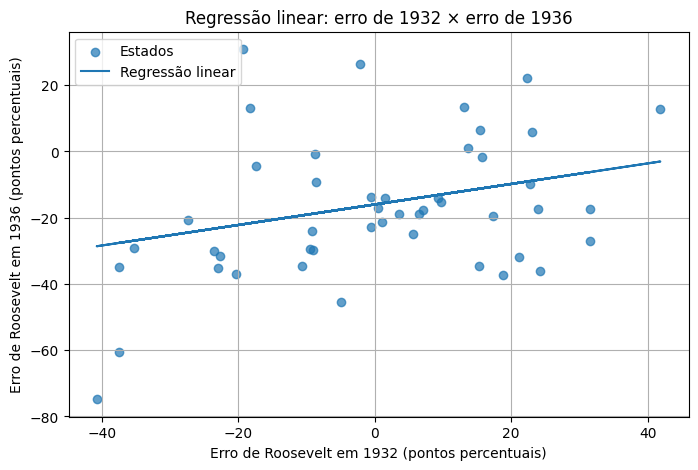

In [ ]:
plt.figure(figsize=(8, 5))

plt.scatter(
    df_reg["erro_Roosevelt_1932"],
    df_reg["erro_Roosevelt"],
    alpha=0.7,
    label="Estados"
)

plt.plot(
    df_reg["erro_Roosevelt_1932"],
    df_reg["erro_1936_previsto"],
    label="Regressão linear"
)

plt.xlabel("Erro de Roosevelt em 1932 (pontos percentuais)")
plt.ylabel("Erro de Roosevelt em 1936 (pontos percentuais)")
plt.title("Regressão linear: erro de 1932 × erro de 1936")
plt.legend()
plt.grid(True)

plt.show()

Criação de um grafico de dispersão, onde cada ponto é um estado. no eixo x temos os pontos percentuais de 32 e no y de 36, já a linha é os valores previstos pela regressão

## 6.10. Métricas Finais Regressão Linear

In [ ]:
print("MÉTRICAS FINAIS")
print("-----------------------------")
print(f"MAE original: {mae_original:.2f} pontos percentuais")
print(f"MAE após regressão: {mae_modelo:.2f} pontos percentuais")
print(f"Redução do MAE: {reducao_erro:.2f} pontos percentuais")
print(f"R² da regressão: {r2:.4f}")

MÉTRICAS FINAIS
-----------------------------
MAE original: 23.28 pontos percentuais
MAE após regressão: 14.91 pontos percentuais
Redução do MAE: 35.97 pontos percentuais
R² da regressão: 0.1311


As métricas indicam que a regressão linear reduziu o erro médio das estimativas de Roosevelt, passando de 23,28 para 14,91 pontos percentuais. Isso representa uma redução de 35,97% no MAE, indicando uma diminuição relevante do erro médio após a aplicação do modelo. O R² de 0,1311 indica que o erro observado em 1932 explica cerca de 13,1% da variação do erro observado em 1936.

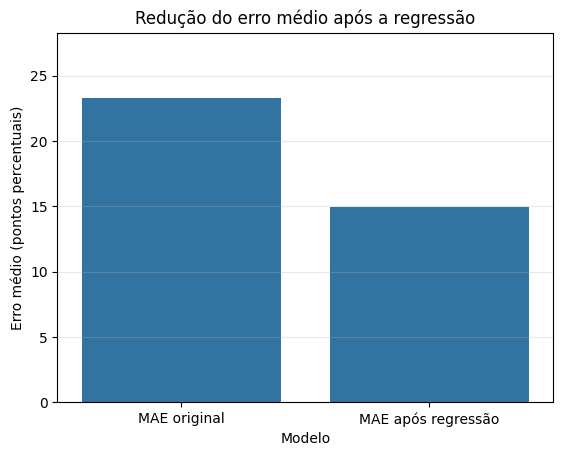

In [ ]:
metricas = ["MAE original", "MAE após regressão"]
valores = [mae_original, mae_modelo]

sns.barplot(x=metricas, y=valores)

plt.title("Redução do erro médio após a regressão")
plt.ylabel("Erro médio (pontos percentuais)")
plt.xlabel("Modelo")

plt.ylim(0, max(valores) + 5)
plt.grid(axis="y", alpha=0.3)

plt.show()

O gráfico apresenta uma comparação entre o MAE (Erro Médio Absoluto) das estimativas originais da pesquisa e das estimativas após a aplicação da regressão linear. Essa visualização permite observar de forma direta a redução do erro obtida pelo modelo, que passou de 23,28 para 14,91 pontos percentuais, representando uma redução de aproximadamente 35,97% no MAE.

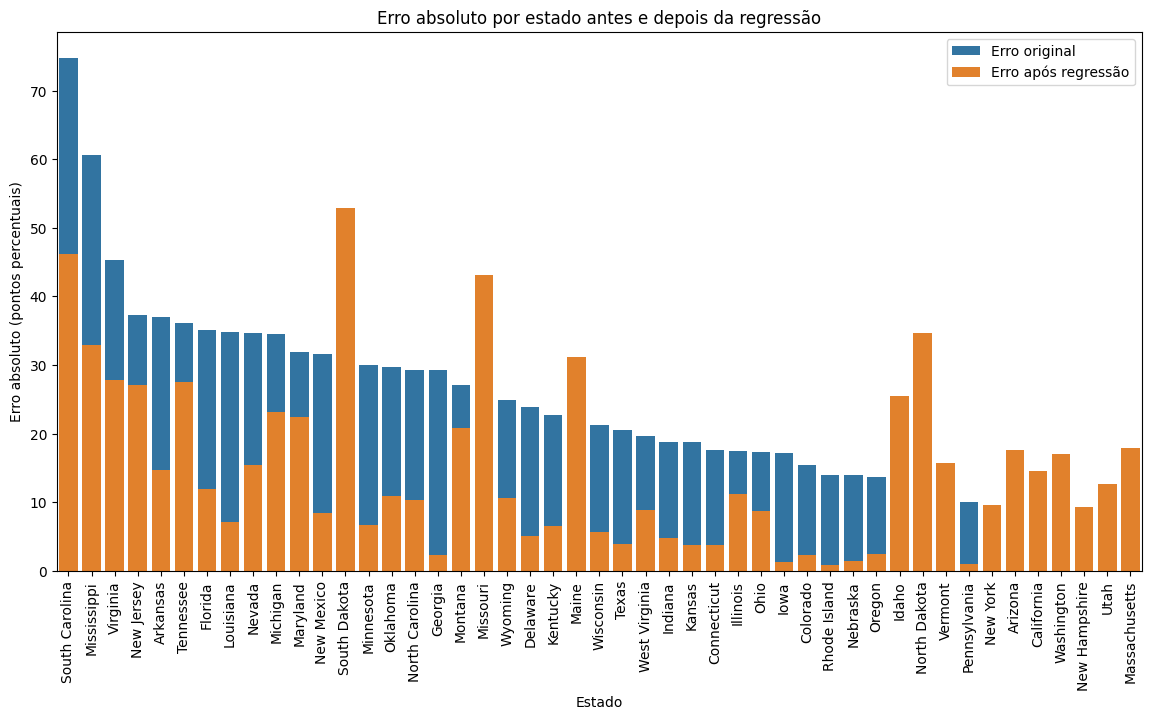

In [ ]:
# Comparação do erro por estado antes e depois da regressão

df_grafico = df_reg[[
    "State - 1936",
    "erro_Roosevelt",
    "erro_1936_previsto"
]].copy()

df_grafico["erro_original_abs"] = df_grafico["erro_Roosevelt"].abs()
df_grafico["erro_corrigido_abs"] = (
    df_grafico["erro_Roosevelt"] - df_grafico["erro_1936_previsto"]
).abs()

df_grafico = df_grafico.sort_values(
    "erro_original_abs",
    ascending=False
)

plt.figure(figsize=(14, 7))

sns.barplot(
    data=df_grafico,
    x="State - 1936",
    y="erro_original_abs",
    label="Erro original"
)

sns.barplot(
    data=df_grafico,
    x="State - 1936",
    y="erro_corrigido_abs",
    label="Erro após regressão"
)

plt.title("Erro absoluto por estado antes e depois da regressão")
plt.xlabel("Estado")
plt.ylabel("Erro absoluto (pontos percentuais)")
plt.xticks(rotation=90)
plt.legend()

plt.show()

O gráfico apresenta o erro absoluto das estimativas de Roosevelt em cada estado, comparando os valores originais da pesquisa com os valores após a correção baseada na regressão linear. Essa visualização permite identificar, de forma mais detalhada, em quais estados a aplicação do modelo contribuiu para reduzir o erro e onde a diferença entre a estimativa e o resultado real permaneceu elevada.

## 6.11. Estimativa Final Regressão Linear

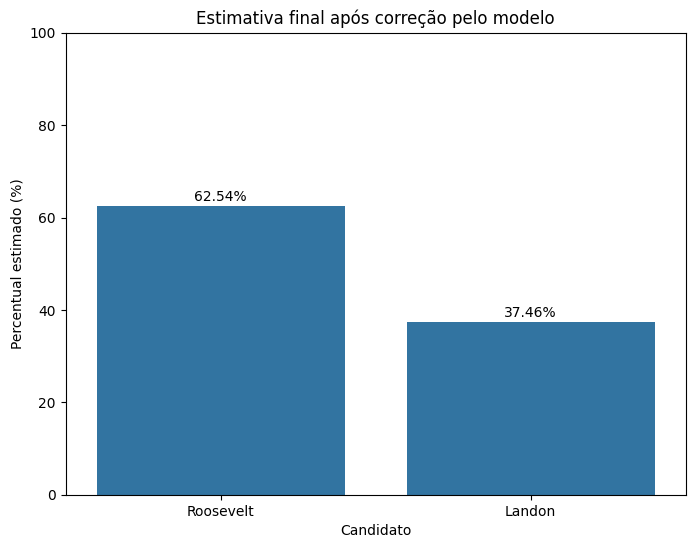

In [ ]:
# Comparação da estimativa final entre Roosevelt e Landon

roosevelt_final = df_reg["Roosevelt_corrigido_modelo"].mean()

landon_final = 100 - roosevelt_final

resultado_final = pd.DataFrame({
    "Candidato": ["Roosevelt", "Landon"],
    "Estimativa (%)": [roosevelt_final, landon_final]
})

plt.figure(figsize=(8, 6))

ax = sns.barplot(
    data=resultado_final,
    x="Candidato",
    y="Estimativa (%)"
)

for i, valor in enumerate(resultado_final["Estimativa (%)"]):
    ax.text(i, valor + 1, f"{valor:.2f}%", ha="center")

plt.title("Estimativa final após correção pelo modelo")
plt.xlabel("Candidato")
plt.ylabel("Percentual estimado (%)")
plt.ylim(0, 100)

plt.show()

O gráfico apresenta a estimativa final das intenções de voto para Roosevelt e Landon após a aplicação da correção baseada na regressão linear. A comparação permite visualizar como as métricas e o ajuste do modelo modificaram a estimativa inicial da pesquisa. O candidato com maior percentual na estimativa final representa o Roosevelt como vencedor, condizendo com o resultado da época.

## 6.12. Arvore de Decisão, Floresta Aleatória e Gradient Boosting

###6.12.1 Criando os modelos

In [ ]:
modelos = {
    'Árvore de Decisão' : DecisionTreeRegressor(random_state= 42),
    'Floresta Aleatória' : RandomForestRegressor(random_state=42),
    'Gradient Boosting' : GradientBoostingRegressor(random_state=42)
}

for nome, md in modelos.items():
  md.fit(x_train, y_train)
  print(f'{nome} treinado')

Árvore de Decisão treinado
Floresta Aleatória treinado
Gradient Boosting treinado


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:1389: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples,), for example using ravel().
  return fit_method(estimator, *args, **kwargs)
/usr/local/lib/python3.13/dist-packages/sklearn/ensemble/_gb.py:672: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)  # TODO: Is this still required?


Nesta célula, treinamos os três modelos de Machine Learning utilizando os dados de treinamento e verificamos se cada algoritmo foi treinado corretamente.

### 6.12.2 Prevendo

In [ ]:
previsoes = {nome: md.predict(x_test) for nome, md in modelos.items()}
print("Valores Reais: ", y_test)
for nome, y_pred in previsoes.items():
  print(f"{nome}:{y_pred}")

Valores Reais:      erro_Roosevelt
27      -31.557180
39      -20.566515
26      -37.316876
43       -4.404372
24      -34.734172
36      -74.809444
12      -18.756094
19      -29.947773
4       -17.565321
25       -1.836319
Árvore de Decisão:[-35.14819036 -35.14819036 -19.59943458  13.04150943 -29.35190279
 -60.63583317 -14.03738625 -35.14819036 -18.76837804   6.47096896]
Floresta Aleatória:[-25.79341058 -30.60154147 -20.40087385  14.68091518 -27.25203391
 -50.7011078  -16.83476476 -25.79341058 -19.61362698  -8.29114211]
Gradient Boosting:[-34.69250921 -34.69250921 -19.22699846  11.23885211 -27.45319342
 -59.59002599 -16.32798078 -34.69250921 -18.40115822   1.76240981]


Nesta célula, realizamos previsões com os três modelos utilizando os dados de teste e comparamos os valores estimados com os valores reais de erro de Roosevelt em 1936.

### 6.12.3 Avaliando e Comparando

In [ ]:
resultados = []
for nome, y_pred in previsoes.items():
    mae = mean_absolute_error(y_test.values.ravel(), y_pred)
    r2 = r2_score(y_test.values.ravel(), y_pred)
    resultados.append({
        "Modelo": nome,
        "MAE": round(mae, 4),
        "R²": round(r2, 4)
    })

df_resultados = pd.DataFrame(resultados)
print("Comparação dos Modelos de Regressão:\n")
display(df_resultados)

Comparação dos Modelos de Regressão:



,Modelo,MAE,R²
0,Árvore de Decisão,9.2321,0.6879
1,Floresta Aleatória,9.7969,0.6107
2,Gradient Boosting,8.5102,0.7102


Nesta etapa, comparamos o desempenho dos três modelos de regressão por meio das métricas MAE e R², identificando qual apresentou as previsões mais próximas dos valores reais. O Gradient Boosting obteve o melhor resultado, apresentando o menor MAE e o maior R² entre os modelos avaliados.

### 6.12.4 Visualizando

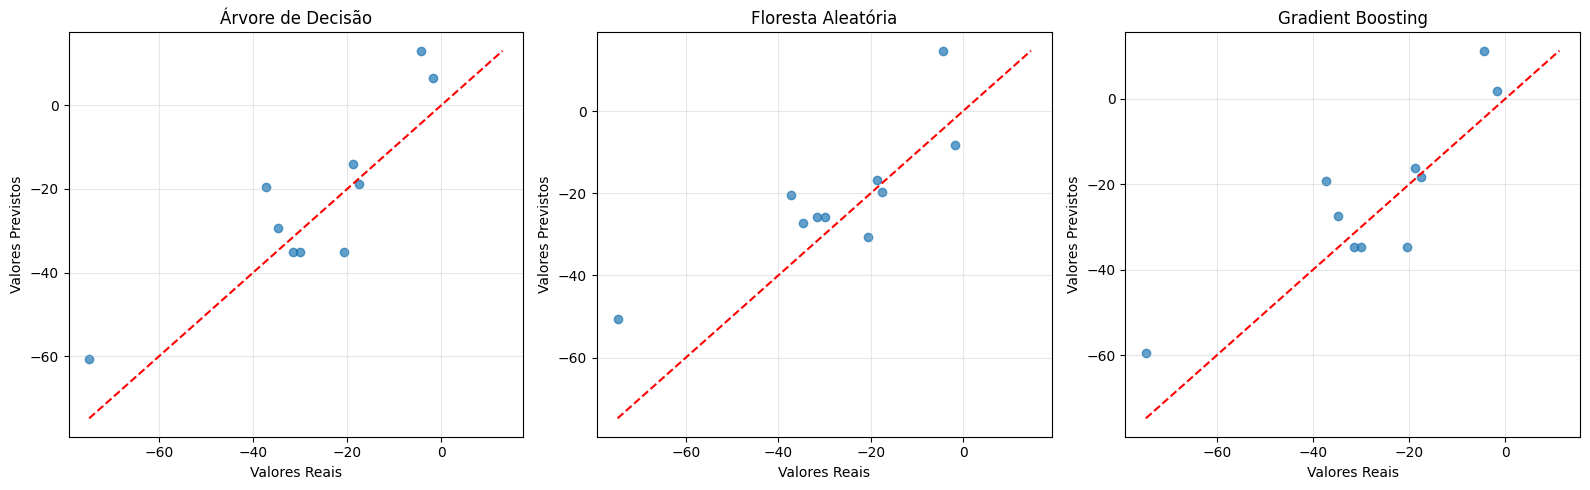

In [ ]:
y_real = y_test.values.ravel()
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, (nome, y_pred) in zip(axes, previsoes.items()):
    ax.scatter(y_real, y_pred, alpha=0.7)
    minimo = min(np.min(y_real), np.min(y_pred))
    maximo = max(np.max(y_real), np.max(y_pred))
    ax.plot([minimo, maximo], [minimo, maximo], 'r--')
    ax.set_title(nome)
    ax.set_xlabel("Valores Reais")
    ax.set_ylabel("Valores Previstos")
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Nesta célula, visualizamos a relação entre os valores reais e os valores previstos pelos três modelos de regressão. Quanto mais próximos os pontos estiverem da linha vermelha, mais precisas são as previsões. O Gradient Boosting apresentou o melhor desempenho geral, com previsões visualmente mais próximas dos valores reais e os melhores resultados nas métricas MAE e R².

##6.13. Interpretando

A análise mostra que técnicas de Machine Learning podem contribuir para identificar padrões nos erros históricos das pesquisas eleitorais e melhorar suas estimativas. Inicialmente, a Regressão Linear simples conseguiu reduzir o MAE de 23,28 para 14,91 pontos percentuais, representando uma redução de aproximadamente 35,97%. Entretanto, seu R² de 0,1311 demonstrou uma capacidade explicativa limitada, indicando que o erro observado em 1932, isoladamente, não era suficiente para explicar grande parte da variação do erro de 1936.

Posteriormente, foram implementados e avaliados outros três modelos de regressão: Árvore de Decisão, Floresta Aleatória e Gradient Boosting. Entre eles, o Gradient Boosting apresentou o melhor desempenho, com MAE de 8,5102 e R² de 0,7102, seguido pela Árvore de Decisão, com MAE de 9,2321 e R² de 0,6879. A Floresta Aleatória apresentou MAE de 9,7969 e R² de 0,6107.

Considerando as métricas obtidas nas avaliações apresentadas, o Gradient Boosting foi o modelo com os melhores resultados gerais, demonstrando maior capacidade de aproximar suas previsões dos valores reais. Esse resultado também evidencia que algoritmos capazes de combinar vários modelos podem identificar padrões mais complexos nos dados.

Por fim, o trabalho demonstra, na prática, as principais etapas de um projeto de Ciência de Dados e Machine Learning: preparação e transformação dos dados, análise exploratória, cálculo de erros, construção de modelos preditivos, avaliação por métricas e interpretação dos resultados. Apesar dos resultados positivos, a quantidade limitada de observações e a necessidade de considerar outras variáveis mostram que ainda existem oportunidades para aprimorar os modelos e obter previsões mais confiáveis.